# Sleep staging on wearable signals — real-dataset-only pipeline

This notebook runs supervised wearable sleep-staging baselines and opt-in ablations using the real dataset at:

`/home/rj2826/ai-research/sleep/02. A Multi-Night Instantaneous Heart Rate and Accelerometry Dataset with EEG Sleep Stage Labels/a-multi-night-instantaneous-heart-rate-and-accelerometry-dataset-with-eeg-sleep-stage-labels-1.0.0`

**Real-data-only policy:** this notebook contains no synthetic-data generator, synthetic training mode, or synthetic end-to-end test dataset. If the configured dataset path is missing or the expected real files cannot be discovered, execution stops with an error.

## Research scope

This study concerns **healthy-population longitudinal sleep monitoring**. The dataset excluded participants with severe untreated sleep disorders or major cardiovascular conditions, so it cannot support claims about sleep-disorder detection or clinical-level reliability. The reported SLAMSS-IFS paper results (71.04% accuracy, 0.7079 Macro-F1) are an external reference, not results reproduced by this notebook.

## Before running

1. Confirm that the path above exists on the Ubuntu machine running Jupyter.
2. Run all cells from top to bottom. The baseline cells preserve the recorded experiment; the new ablation suite is opt-in and defaults off.
3. Inspect discovered subject/night counts, raw label counts, alignment diagnostics, the QC table, and the saved subject split before interpreting metrics.
4. The notebook uses one subject-level train/validation/test split. The test partition must not be used for model selection.
5. Verify label encoding and timestamp alignment against the dataset's official documentation. Automated checks can flag inconsistencies but cannot replace documentation verification.

The notebook evaluates supervised wearable sleep staging and explicitly reports that the prior JEPA experiment did not improve over supervised learning. New requested methods are isolated as opt-in experiments.


## Protocol audit status
This notebook has been patched in this revision for the opt-in behavior and configuration fields listed below. The requested full F1–F7 acceptance protocol is not yet verified end-to-end; do not interpret this artifact as a validated scientific pipeline until the test cell and all real-data gates pass.

Primary test evaluation must be performed once after model selection. Test-subject personalization and permutation analyses are exploratory (test looked at).


This revision adds separately toggleable, validation-selected ablations. The saved baseline outputs below are historical and are not results for the revised code; rerun from the first cell on the documented environment before reporting new results. No requested ablation is claimed to have executed.

## 1. Setup and run flags

In [ ]:
# pip install numpy pandas scipy scikit-learn torch tqdm matplotlib
from __future__ import annotations
import json, math, os, random, time, zipfile, warnings, platform, hashlib, pickle, copy, zlib, tempfile, shutil, datetime, re, sys
from collections import OrderedDict
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from typing import Optional

import numpy as np, pandas as pd, scipy.io
from scipy.stats import wilcoxon
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------------ real-data-only run configuration
DATA_PATH = '/home/rj2826/ai-research/sleep/02. A Multi-Night Instantaneous Heart Rate and Accelerometry Dataset with EEG Sleep Stage Labels/a-multi-night-instantaneous-heart-rate-and-accelerometry-dataset-with-eeg-sleep-stage-labels-1.0.0'  # exact real dataset path supplied by the user
WORK_BASE = os.environ.get("SLEEP_WORK_DIR", "/home/rj2826/ai-research/sleep/sleepchannelnet_v8_preprocessing_audit_work")

RUN_LABEL = "REAL"
TITLE_TAG = ""
def banner(msg=""):
    print("=" * 100)
    print("REAL DATA ONLY | full dataset mode")
    if msg:
        print(msg)

def show(df):
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string() if hasattr(df, "to_string") else df)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
banner(f"torch {torch.__version__} | device {DEVICE} | cuda devices: {torch.cuda.device_count() if torch.cuda.is_available() else 0} | run label: {RUN_LABEL}")

## 2. Constants, feature registry, label encodings, tasks
Everything that defines *meaning* (what a raw label is, which channels exist, how classes are grouped) lives in registries so it can be inspected, hashed and tested.

In [ ]:
UNKNOWN = -100                                   # ignore label (loss / metrics); never shifts time positions
CANON_STAGES = ("Wake", "N1", "N2", "N3", "REM")   # canonical stage ids 0..4 used everywhere inside the cache

BASE_NODES = ["hr", "hr_slope", "hr_std", "acc_x", "acc_y", "acc_z", "acc_mag", "acc_jerk", "acc_energy", "hr_density"]
INTERACTION_NODES = ["hr_reactivity", "motion_artifact_mask", "hr_motion_coupling"]
NODES_ALL = BASE_NODES + INTERACTION_NODES
HR_G = {"hr", "hr_slope", "hr_std"}
MO_G = {"acc_x", "acc_y", "acc_z", "acc_mag", "acc_jerk", "acc_energy"}
NODE_SETS = {"all10": tuple(BASE_NODES), "all13": tuple(NODES_ALL), "raw5": ("hr", "acc_x", "acc_y", "acc_z", "hr_density")}
META_DIM = 5      # [raw IHR rate, raw motion rate, elapsed time, IHR coverage, motion coverage]

FEATURE_REGISTRY = pd.DataFrame([
    ("hr",          "IHR (bpm), linearly interpolated to 1 Hz, per-night robust-scaled",   "measurement (resampled)"),
    ("hr_slope",    "gradient of interpolated IHR",                                         "PROXY derived from IHR - not HRV"),
    ("hr_std",      "30 s rolling std of interpolated IHR",                                 "PROXY derived from IHR - not HRV"),
    ("acc_x/y/z",   "accelerometer axes, clipped and interpolated, per-night robust-scaled", "measurement (resampled)"),
    ("acc_mag",     "vector magnitude of the three axes",                                   "derived from accelerometer"),
    ("acc_jerk",    "abs. first difference of magnitude, log-compressed",                   "derived from accelerometer"),
    ("acc_energy",  "30 s rolling mean of squared deviation from median magnitude, log",    "derived from accelerometer"),
    ("hr_density",  "raw IHR samples per 30 s (before interpolation)",                      "device sampling behaviour - NOT physiology; possible confound"),
    ("hr_reactivity", "forward 60 s HR change; retrospective feature with look-ahead", "derived HR; non-causal"),
    ("motion_artifact_mask", "sigmoid motion weight in [0,1], applied to HR channels", "derived HR + accelerometry"),
    ("hr_motion_coupling", "centered rolling 60 s correlation of detrended HR and motion", "derived HR + accelerometry; non-causal"),
], columns=["feature", "definition", "provenance"])

# ------------------------------------------------------------------ label encodings
class LabelEncodingError(ValueError): pass

@dataclass(frozen=True)
class LabelEncoding:
    name: str
    raw_to_stage: tuple          # ((raw_code, canonical_stage_id), ...)
    unknown_raw: tuple           # raw codes meaning "unknown / not scored"
    evidence: str = ""
    def mapping(self): return dict(self.raw_to_stage)
    def validate(self):
        m = self.mapping()
        if not m: raise LabelEncodingError(f"encoding {self.name!r}: empty mapping")
        for r, s in m.items():
            if int(r) != r or int(s) != s: raise LabelEncodingError(f"encoding {self.name!r}: non-integer entry {(r, s)}")
            if s not in range(len(CANON_STAGES)): raise LabelEncodingError(f"encoding {self.name!r}: stage id {s} not in 0..{len(CANON_STAGES)-1}")
        if len(set(m)) != len(m): raise LabelEncodingError(f"encoding {self.name!r}: duplicate raw codes")
        missing = [CANON_STAGES[i] for i in range(len(CANON_STAGES)) if i not in set(m.values())]
        if missing: raise LabelEncodingError(f"encoding {self.name!r}: stages {missing} are not reachable (REM must be mapped)")
        if set(self.unknown_raw) & set(m): raise LabelEncodingError(f"encoding {self.name!r}: a raw code is both mapped and 'unknown'")
        return self
    def fingerprint(self): return hashlib.sha1(json.dumps([self.name, sorted(self.raw_to_stage), sorted(self.unknown_raw)]).encode()).hexdigest()[:10]

LABEL_ENCODINGS = {
    "physionet_doc_v1": LabelEncoding(
        "physionet_doc_v1", ((0, 0), (1, 1), (2, 2), (3, 3), (4, 4)), (5,),
        evidence="Dataset documentation (Datasets_Informations): 'encoded as integers (0 = Wake, 1 = N1, 2 = N2, 3 = N3, 4 = REM, 5 = Unknown)', same scheme for dreem_label and expert_label.").validate(),
}
def get_encoding(spec):
    if isinstance(spec, LabelEncoding): return spec.validate()
    if spec in LABEL_ENCODINGS: return LABEL_ENCODINGS[spec]
    raise LabelEncodingError(f"unknown label encoding {spec!r}; registered: {sorted(LABEL_ENCODINGS)}. Register a LabelEncoding only with documentary evidence.")

# ------------------------------------------------------------------ tasks (class groupings of the canonical stages)
TASKS = {
    "5class": dict(names=CANON_STAGES, grouping={"Wake": [0], "N1": [1], "N2": [2], "N3": [3], "REM": [4]}),
    "4class": dict(names=("Wake", "Light", "Deep", "REM"), grouping={"Wake": [0], "Light": [1, 2], "Deep": [3], "REM": [4]}),
}
def task_info(task):
    if task not in TASKS: raise ValueError(f"unknown task {task!r}; choose from {sorted(TASKS)}")
    t = TASKS[task]; names = tuple(t["names"]); lut = np.full(len(CANON_STAGES), -1, np.int64)
    for ci, nm in enumerate(names):
        for st in t["grouping"][nm]:
            assert lut[st] == -1, f"stage {st} assigned twice in task {task}"; lut[st] = ci
    assert (lut >= 0).all(), f"task {task}: every canonical stage must belong to exactly one class"
    return names, len(names), lut
for _t in TASKS: task_info(_t)
print("registered encodings:", sorted(LABEL_ENCODINGS), "| tasks:", {t: TASKS[t]["grouping"] for t in TASKS})
show(FEATURE_REGISTRY)

## 3. Configuration (frozen)
The configuration is a **frozen dataclass created once**; later cells cannot mutate it (a final assertion checks its hash). Experiment variants are created with `replace(cfg, ...)`. There is no cross-validation parameter: the split is one deterministic subject-level 70 / 15 / 15 partition.

In [ ]:
@dataclass(frozen=True)
class Config:
    data_path: str = DATA_PATH
    work_base: str = WORK_BASE
    seed: int = 42                        # training seed of THIS run (the split seed is separate and fixed)
    # labels / task
    label_encoding: str = "physionet_doc_v1"
    label_source: str = "expert"          # "expert" | "dreem"  (strict: no fallback). Check which one the base paper evaluated.
    task: str = "4class"                  # "4class" | "5class"
    # alignment
    tz: str = "America/New_York"          # documented: recStart stored as US Eastern local time
    allow_unverified_alignment: bool = False   # False: nights without a parseable recStart are EXCLUDED (never guessed)
    time_offset_s: float = 0.0
    align_tol_epochs: int = 2
    min_align_corr: float = 0.05
    max_alignment_failure_frac: float = 0.20
    primary_model: str = "SleepChannelNet (complete graph)"
    run_permutation_importance: bool = True
    run_personalization: bool = False
    # preprocessing
    epoch_sec: int = 30
    fs: int = 1
    max_gap_hr_s: float = 120.0
    hr_outlier_method: str = "std3"  # "std3" | "mad3" | "none"; applied after physiological 30-200 bpm bounds
    max_gap_motion_s: float = 10.0
    min_epoch_coverage: float = 0.5
    motion_floor: float = 0.005
    min_epochs: int = 600                 # >= 5 h
    min_usable_frac: float = 0.6
    # subject-level split (one deterministic partition)
    split_seed: int = 0
    split_fracs: tuple = (0.70, 0.15, 0.15)   # train / val / test subjects
    min_subjects: int = 10
    min_per_eval_partition: int = 2
    subject_limit: Optional[int] = None   # smoke runs only
    # model
    model_type: str = "channel_attn"      # "channel_attn" | "cnn_gru"
    graph_mode: str = "complete"          # "complete" | "modality" | "identity"
    nodes: tuple = tuple(BASE_NODES)
    bidirectional: bool = True
    temporal_encoder: str = "gru"      # "gru" (legacy/default) | "transformer" (JEPA temporal transfer)
    use_freq: bool = True
    use_time: bool = True
    use_hr_motion_features: bool = False
    transition_lambda: float = 0.0
    use_viterbi_decoding: bool = False
    entropy_adaptation: bool = True
    emb_dim: int = 64
    heads: int = 4
    gat_layers: int = 2
    gru_hidden: int = 96
    dropout: float = 0.3
    # training
    seq_len: int = 240
    windows_per_night: int = 6
    batch_size: int = 16
    epochs: int = 40
    patience: int = 10
    lr: float = 1e-3
    weight_decay: float = 1e-2
    use_class_weights: bool = True
    amp: bool = True                      # used only on CUDA
    max_skipped_step_frac: float = 0.05   # abort if more optimizer steps than this are skipped for non-finite gradients
    infer_mode: str = "auto"              # "auto" (chosen on VALIDATION) | "full" | "sliding"
    infer_stride_frac: float = 0.5
    seeds: tuple = (42,)                  # training-seed replicates on the SAME split (not cross-validation)
    multi_gpu: bool = True                # optional DataParallel for TRAINING only; default off
    max_ram_gb: float = 6.0               # preloaded training store must fit; eval stores are lazy
    lru_nights: int = 32
    n_boot: int = 1000
    resume: bool = True
    # baselines
    gbm_context: int = 4
    gbm_max_rows: int = 300000
    # personalization (fixed a priori, never tuned on test subjects)
    adapt_ks: tuple = (1, 2)
    adapt_epochs: int = 5
    adapt_lr: float = 1e-4
    adapt_windows: int = 12
    adapt_scope: str = "all"              # "all" | "head"
    adapt_control: bool = True

cfg = Config()

_RUNTIME_FIELDS = {"data_path", "work_base", "resume", "n_boot", "seeds", "multi_gpu", "max_ram_gb", "lru_nights",
                   "run_permutation_importance", "run_personalization", "primary_model",
                   "use_viterbi_decoding"}
def _h(obj, n=10): return hashlib.sha1(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:n]
def cfg_hash(c): return _h({k: v for k, v in asdict(c).items() if k not in _RUNTIME_FIELDS and not (k == "temporal_encoder" and v == "gru")})
PREP_VERSION = "v6.0"      # content hashes + alignment offset/gate
PREP_FIELDS = ("epoch_sec", "fs", "tz", "max_gap_hr_s", "max_gap_motion_s", "min_epoch_coverage", "motion_floor",
               "hr_outlier_method",
               "min_epochs", "min_usable_frac", "label_source", "allow_unverified_alignment",
               "time_offset_s", "align_tol_epochs", "min_align_corr", "max_alignment_failure_frac")
def prep_config(c): return {k: getattr(c, k) for k in PREP_FIELDS}

CFG_HASH_AT_START = cfg_hash(cfg)
WORK = Path(cfg.work_base + "_" + RUN_LABEL); WORK.mkdir(parents=True, exist_ok=True)
CLASS_NAMES, K, _LUT = task_info(cfg.task)
Lx = cfg.epoch_sec * cfg.fs

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(cfg.seeds[0])
banner(f"task={cfg.task} classes={CLASS_NAMES} label_encoding={cfg.label_encoding} label_source={cfg.label_source} cfg_hash={CFG_HASH_AT_START} work={WORK}")

In [ ]:
# STEP 0 — executable configuration identity tests (before any real-data/cache work)
# Runtime toggles must not change cfg_hash; preprocessing fields must change prep_config/cache identity.
def _step0_check():
    runtime_fields = ("run_permutation_importance", "run_personalization", "primary_model")
    prep_fields = ("time_offset_s", "align_tol_epochs", "min_align_corr", "max_alignment_failure_frac")
    base = cfg
    base_hash = cfg_hash(base)
    for field in runtime_fields:
        changed = replace(base, **{field: (not getattr(base, field)) if isinstance(getattr(base, field), bool) else "different-primary"})
        assert cfg_hash(changed) == base_hash, f"runtime field unexpectedly changed cfg_hash: {field}"
        print("PASS runtime cfg_hash invariant:", field)
    base_prep = _h([PREP_VERSION, prep_config(base)], 16)
    for field in prep_fields:
        value = getattr(base, field)
        changed_value = value + 1 if isinstance(value, (int, float)) else "changed"
        changed = replace(base, **{field: changed_value})
        changed_prep = _h([PREP_VERSION, prep_config(changed)], 16)
        assert changed_prep != base_prep, f"preprocessing field failed to change cache identity: {field}"
        print("PASS preprocessing cache identity changes:", field)
_step0_check()


PASS runtime cfg_hash invariant: run_permutation_importance
PASS runtime cfg_hash invariant: run_personalization
PASS runtime cfg_hash invariant: primary_model
PASS preprocessing cache identity changes: time_offset_s
PASS preprocessing cache identity changes: align_tol_epochs
PASS preprocessing cache identity changes: min_align_corr
PASS preprocessing cache identity changes: max_alignment_failure_frac


## 4. Label mapping and verification (pure functions, unit-tested at the end)
Order of operations: **raw values -> explicit mapping to canonical stages -> only then validity filtering**. NaN, infinite, non-integer, unexpected and documented-unknown raw values are all counted separately and all become `UNKNOWN` (-100); the array length never changes, so time alignment is preserved.

### Label-source decision required

The user must confirm whether the reference paper used `expert_label` or `dreem_label`.
This notebook does not infer or guess the paper's label source. The selected source is recorded in
`cfg.label_source`; if both sources are available, agreement should be reported before proceeding.


In [ ]:
def map_raw_labels(raw, enc: LabelEncoding):
    """raw label vector -> (canonical stage ids with UNKNOWN for anything not a documented stage, diagnostics)."""
    raw = np.asarray(raw, dtype=float).ravel()
    stage = np.full(raw.shape, UNKNOWN, dtype=np.int64)
    finite = np.isfinite(raw)
    integer = finite & (np.abs(raw - np.round(raw)) < 1e-9)
    rawi = np.where(integer, np.round(raw), np.nan)
    for r, s in enc.mapping().items(): stage[integer & (rawi == r)] = s
    mapped = stage != UNKNOWN
    unknown = integer & np.isin(rawi, list(enc.unknown_raw))
    unexpected = integer & ~mapped & ~unknown
    vals, cnts = np.unique(rawi[integer], return_counts=True)
    diag = dict(n=int(raw.size), n_nonfinite=int((~finite).sum()), n_non_integer=int((finite & ~integer).sum()),
                n_unknown_raw=int(unknown.sum()), n_unexpected=int(unexpected.sum()),
                unexpected_values=[int(v) for v in sorted(set(rawi[unexpected]))], raw_counts={str(int(v)): int(c) for v, c in zip(vals, cnts)})
    return stage, diag

def verify_label_encoding(total: dict, enc: LabelEncoding, max_unexpected_frac=0.005, max_unknown_frac=0.25, rem_plausible=(0.05, 0.40)):
    """Dataset-level sanity check of the encoding against the observed raw counts. Raises LabelEncodingError with what is needed."""
    n = max(int(total.get("n", 0)), 1); rc = {int(k): v for k, v in total.get("raw_counts", {}).items()}
    bad = total.get("n_unexpected", 0) + total.get("n_non_integer", 0)
    need = ("Needed to resolve this: the dataset documentation's description of the labels.mat variables (dreem_label / expert_label) or the authors' "
            "hypnogram export code, plus the printed raw value counts above.")
    msg_counts = f"observed raw counts: {dict(sorted(rc.items()))}; non-finite={total.get('n_nonfinite', 0)}; non-integer={total.get('n_non_integer', 0)}; unexpected={total.get('n_unexpected', 0)}"
    if bad / n > max_unexpected_frac:
        raise LabelEncodingError(f"{bad / n:.2%} of label values are outside encoding {enc.name!r} ({msg_counts}). {need}")
    m = enc.mapping(); inv = {s: [r for r, ss in m.items() if ss == s] for s in set(m.values())}
    absent = [CANON_STAGES[s] for s in range(len(CANON_STAGES)) if sum(rc.get(r, 0) for r in inv[s]) == 0]
    if absent: raise LabelEncodingError(f"stages never observed under encoding {enc.name!r}: {absent} ({msg_counts}). The encoding may be wrong (e.g. 1-based or REM coded differently). {need}")
    unk = sum(rc.get(r, 0) for r in enc.unknown_raw) / n
    if unk > max_unknown_frac:
        raise LabelEncodingError(f"raw code(s) {enc.unknown_raw} are documented as UNKNOWN but make up {unk:.1%} of all epochs ({msg_counts}). If they are really a sleep stage (e.g. REM) the documented encoding is wrong. {need}")
    stage_n = {CANON_STAGES[s]: sum(rc.get(r, 0) for r in inv[s]) for s in inv}; sleep = max(sum(v for k, v in stage_n.items() if k != "Wake"), 1)
    warns = []
    rem_share = stage_n["REM"] / sleep
    if not (rem_plausible[0] <= rem_share <= rem_plausible[1]):
        warns.append(f"REM is {rem_share:.1%} of sleep epochs (physiologically expected roughly 15-25%): double-check the encoding.")
    return dict(stage_counts=stage_n, unknown_frac=unk, rem_share_of_sleep=rem_share, warnings=warns)

## 5. Readers: recStart, CSV, labels
* `recStart` is documented as a human-readable **US Eastern** string. It is converted exactly like the dataset's own example (`pytz ... localize`, which resolves ambiguous DST times to standard time). Numeric values are accepted only if they look like Unix seconds. Anything else returns `None`; **there is no fallback to the signal start** (v3 silently guessed it).
* Epoch *k* covers `[recStart + 30(k-1), recStart + 30k)`, i.e. `k = floor((t - recStart)/30) + 1`.

In [ ]:
def _extract_string(v):
    if isinstance(v, str): return v
    if isinstance(v, np.ndarray):
        if v.dtype.kind in "US": return "".join(str(x) for x in v.ravel())
        for x in v.ravel():
            s = _extract_string(x)
            if s: return s
    return None

def parse_rec_start(mat: dict, tz: str):
    """-> (unix_seconds or None, format_tag_or_reason). Never guesses."""
    v = mat.get("recStart")
    if v is None: return None, "recStart variable missing"
    s = _extract_string(np.asarray(v, dtype=object) if not isinstance(v, np.ndarray) else v)
    if s is not None and s.strip():
        s = s.strip()
        try:
            t = pd.Timestamp(s)
        except Exception:
            return None, f"unparseable recStart string {s!r}"
        if t.tzinfo is None:
            t = t.tz_localize(tz, ambiguous=False, nonexistent=pd.Timedelta("1h"))      # == pytz localize(is_dst=False), as in the dataset documentation
            return float(t.timestamp()), "string_local_tz"
        return float(t.timestamp()), "string_with_offset"
    a = np.asarray(v)
    if a.size and a.dtype.kind in "fiu":
        x = float(a.flat[0])
        if np.isfinite(x) and 1e9 < x < 1e11: return x, "numeric_unix_seconds"
        return None, f"numeric recStart {x!r} is not recognisable Unix seconds (MATLAB datenum / ms are not documented, so not guessed)"
    return None, "recStart has an unsupported type"

def read_label_vector(mat: dict, where: str, source: str):
    key = {"expert": "expert_label", "dreem": "dreem_label"}[source]
    if key not in mat: raise KeyError(f"{where}: '{key}' not found (label_source={source!r}). Keys: {[k for k in mat if not k.startswith('__')]}")
    a = np.asarray(mat[key]).squeeze()
    if a.ndim == 0: a = a.reshape(1)
    if a.ndim != 1 or a.size == 0 or a.dtype.kind not in "fiu": raise ValueError(f"{where}: '{key}' is not a non-empty numeric vector (shape {a.shape}, dtype {a.dtype})")
    return a.astype(float), key

def read_csv_flex(path, cols):
    """Headered or headerless CSV -> (DataFrame[cols], diagnostics). Timestamps are expected in Unix seconds (documented)."""
    raw = pd.read_csv(path, header=None); n_raw = len(raw)
    if raw.shape[1] < len(cols): raise ValueError(f"{path}: expected >= {len(cols)} columns")
    df = raw.iloc[:, :len(cols)]
    if pd.to_numeric(df.iloc[0], errors="coerce").isna().any(): df = df.iloc[1:]
    df.columns = cols
    df = df.apply(pd.to_numeric, errors="coerce").dropna(); df = df[np.isfinite(df.to_numpy()).all(axis=1)].sort_values("time")
    n_valid = len(df); df = df.groupby("time", as_index=False).median()
    if len(df) < 10: raise ValueError(f"{path}: fewer than 10 valid rows")
    ms = bool(df.time.median() > 1e11)
    if ms: df["time"] = df["time"] / 1000.0                              # NOT documented: flagged in QC
    return df.reset_index(drop=True), dict(n_rows_raw=int(n_raw), n_rows_valid=int(n_valid), n_dup_timestamps=int(n_valid - len(df)), ms_timestamps=ms)

## 6. Preprocessing: grid construction, gap masking, alignment diagnostics
* The 1 Hz grid starts at `recStart`; epoch *k* is rows `30(k-1) ... 30k-1`. HR, motion and labels therefore share one clock (the dataset recorded both devices on one iPhone).
* **Gaps are masked, not padded**: epochs with insufficient real data get label `UNKNOWN` and zeroed inputs; positions are never removed.
* Normalisation is per night and label-free (median/IQR of that night only; no other night is touched).
* Labels reach this function already mapped (Section 4), *before* any validity filtering.
* Alignment diagnostics (offsets of the first/last samples relative to `recStart`, coverage, and a label-motion lag check) are **reported, not used as features**. The lag check uses labels only for QC.

In [ ]:
def robust_scale(v, floor):
    med = np.nanmedian(v); iqr = np.nanpercentile(v, 75) - np.nanpercentile(v, 25)
    return np.clip(np.nan_to_num((v - med) / max(float(iqr), floor)), -10, 10).astype(np.float32)

def nearest_gap(t_raw, grid):
    i = np.searchsorted(t_raw, grid)
    lo = t_raw[np.clip(i - 1, 0, len(t_raw) - 1)]; hi = t_raw[np.clip(i, 0, len(t_raw) - 1)]
    return np.minimum(np.abs(grid - lo), np.abs(grid - hi))

def roll(v, w, fn): return getattr(pd.Series(v).rolling(w, center=True, min_periods=1), fn)().fillna(0).to_numpy()

def alignment_qc(energy_ep, y, max_lag=720, step=4):
    """Lag (epochs) maximising corr(motion energy, wake indicator). DIAGNOSTIC ONLY (uses labels); nan if undefined."""
    wake = (y == 0).astype(float); ok = y >= 0; e, w = energy_ep[ok], wake[ok]
    min_ov = min(300, len(e) // 2)
    if len(e) < 100 or w.std() == 0: return np.nan, np.nan, np.nan
    def corr(lag):
        if len(e) - abs(lag) < min_ov: return -9
        a, b = (e[lag:], w[:len(w) - lag]) if lag >= 0 else (e[:len(e) + lag], w[-lag:])
        if a.std() == 0 or b.std() == 0: return -9
        return float(np.corrcoef(a, b)[0, 1])
    lags = sorted(set(range(-max_lag, max_lag + 1, step)) | {0}); cs = [corr(l) for l in lags]; j = int(np.argmax(cs))
    return lags[j], cs[j], corr(0)

def process_night(hr, mot, stage, rec_start, c: Config):
    """hr/mot DataFrames, stage = canonical stage ids (UNKNOWN for unknown), rec_start = verified Unix seconds."""
    n_ep = len(stage); n = n_ep * Lx; fs = c.fs; grid = np.arange(n) / fs
    t_hr_raw, t_mo = hr.time.to_numpy() - rec_start, mot.time.to_numpy() - rec_start
    edges = np.linspace(0, n / fs, n + 1)
    raw_counts = np.histogram(t_hr_raw, bins=edges)[0].astype(float)                 # raw IHR samples per second BEFORE interpolation
    mo_counts = np.histogram(t_mo, bins=np.linspace(0, n / fs, n_ep + 1))[0].astype(float)
    h = hr.hr.to_numpy()
    # Keep the physiological plausibility filter separate from statistical outlier handling.
    keep = np.isfinite(h) & (h >= 30) & (h <= 200)
    method = getattr(c, "hr_outlier_method", "std3")
    if method == "std3":
        if keep.sum() > 10 and h[keep].std() > 0:
            keep &= np.abs((h - h[keep].mean()) / h[keep].std()) <= 3
    elif method == "mad3":
        if keep.sum() > 10:
            med = np.median(h[keep])
            mad = np.median(np.abs(h[keep] - med))
            robust_sigma = 1.4826 * mad
            if robust_sigma > 0:
                keep &= np.abs(h - med) <= 3 * robust_sigma
    elif method == "none":
        pass
    else:
        raise ValueError(f"Unknown hr_outlier_method={method!r}; use 'std3', 'mad3', or 'none'.")
    if keep.sum() < 10: raise ValueError("fewer than 10 valid IHR samples after HR filtering")
    t_hr, hv = t_hr_raw[keep], h[keep]
    hr_i = np.interp(grid, t_hr, hv); ok_hr = nearest_gap(t_hr, grid) <= c.max_gap_hr_s
    comps = []
    for ax_ in "xyz":
        v = mot[ax_].to_numpy(); lo, hi = np.percentile(v, [0.1, 99.9]); comps.append(np.interp(grid, t_mo, np.clip(v, lo, hi)))
    ax, ay, az = comps; mag = np.sqrt(ax ** 2 + ay ** 2 + az ** 2); ok_mo = nearest_gap(t_mo, grid) <= c.max_gap_motion_s
    mf = c.motion_floor; w = Lx
    dyn = np.abs(mag - np.median(mag)); jerk = np.abs(np.diff(mag, prepend=mag[0])) * fs
    hr_detrended = hr_i - pd.Series(hr_i).rolling(60 * fs, center=True, min_periods=2).mean().bfill().ffill().to_numpy()
    motion_detrended = mag - pd.Series(mag).rolling(60 * fs, center=True, min_periods=2).mean().bfill().ffill().to_numpy()
    coupling = pd.Series(hr_detrended).rolling(60 * fs, center=True, min_periods=10).corr(pd.Series(motion_detrended)).fillna(0).to_numpy()
    coupling = np.clip(coupling, -1, 1)
    # Forward 60-s HR response is deliberately retrospective and must not be described as causal.
    reactivity = np.zeros_like(hr_i); look = 60 * fs
    if len(hr_i) > look: reactivity[:-look] = hr_i[look:] - hr_i[:-look]
    artifact_mask = 1.0 / (1.0 + np.exp(np.clip(2.0 * (mag - np.median(mag) - 2.0 * max(mf, 1e-6)), -30, 30)))
    chans = [robust_scale(hr_i, 2.0), robust_scale(np.gradient(hr_i) * fs, 0.05), robust_scale(roll(hr_i, w, "std"), 0.5),
             robust_scale(ax, mf), robust_scale(ay, mf), robust_scale(az, mf), robust_scale(mag, mf),
             robust_scale(np.log1p(jerk / mf), 0.1), robust_scale(np.log1p(roll(dyn ** 2, w, "mean") / mf ** 2), 0.1),
             robust_scale(np.log1p(roll(raw_counts, w, "sum")), 0.1),
             robust_scale(reactivity, 2.0), artifact_mask.astype(np.float32), robust_scale(coupling, 0.05)]
    assert len(chans) == len(NODES_ALL)
    sig = np.stack(chans); sig[:3] *= ok_hr; sig[:3] *= artifact_mask[None, :]; sig[3:9] *= ok_mo; sig[10] *= ok_hr; sig[11] *= ok_mo; sig[12] *= (ok_hr & ok_mo)
    X = sig.reshape(len(NODES_ALL), n_ep, Lx).transpose(1, 0, 2).astype(np.float16)
    cov_hr, cov_mo = ok_hr.reshape(n_ep, Lx).mean(1), ok_mo.reshape(n_ep, Lx).mean(1)
    valid = (cov_hr >= c.min_epoch_coverage) & (cov_mo >= c.min_epoch_coverage)
    X[~valid] = 0
    y = stage.astype(np.int64).copy(); n_known = int((y >= 0).sum()); y[~valid] = UNKNOWN
    meta = np.stack([np.log1p(raw_counts.reshape(n_ep, Lx).sum(1) / c.epoch_sec * 10), np.log1p(mo_counts / c.epoch_sec),
                     np.arange(n_ep) * c.epoch_sec / 3600 / 10, cov_hr, cov_mo], 1).astype(np.float32)
    lag, c_best, c0 = alignment_qc(X[:, NODES_ALL.index("acc_energy")].astype(np.float32).mean(1), y)
    span = n_ep * c.epoch_sec
    qc = dict(n_epochs=n_ep, n_label_known=n_known, n_known_masked_by_signal=int(n_known - (y >= 0).sum()), usable_frac=float((y >= 0).mean()),
              cov_hr=float(cov_hr.mean()), cov_motion=float(cov_mo.mean()), rec_start_unix=float(rec_start),
              hr_first_offset_s=float(t_hr_raw.min()), hr_last_offset_s=float(t_hr_raw.max()), motion_first_offset_s=float(t_mo.min()),
              motion_last_offset_s=float(t_mo.max()), label_span_s=float(span),
              signal_ends_before_label_end_s=float(max(span - min(t_hr_raw.max(), t_mo.max()), 0.0)),
              best_lag_epochs=lag, corr_best=c_best, corr_lag0=c0, hr_median=float(np.median(hv)),
              raw_hr_rate_hz=float(len(t_hr_raw) / max(t_hr_raw.max() - t_hr_raw.min(), 1)))
    return X, y, meta, qc

## Preprocessing audit: HR outlier policy

The preprocessing pipeline now exposes `cfg.hr_outlier_method` with three options: `std3` (the original global 3-SD rule), `mad3` (robust median/MAD filtering), and `none` (no statistical filtering, while retaining the physiological 30–200 bpm bounds). This setting is part of the preprocessing fingerprint, so cached nights from different policies are not reused. Run the complete data preparation and model evaluation separately for each condition using the same subject split seed; compare QC, class-wise metrics, and subject-level uncertainty. Do not choose a policy using test performance.

## 7. Dataset validation, fingerprinted cache, QC and the single subject-level split
**Real-data validation (before any training):** the configured path must exist and contain the expected source files; synthetic-marked directories are rejected. The discovered subject/night counts are compared with the dataset documentation.

**Cache identity.** The cache directory name hashes the preprocessing configuration, the label encoding and the dataset root. Every cached night additionally stores a fingerprint of its own source files (path, size, mtime), the preprocessing version and the encoding, and is **validated (keys, shapes, dtypes, finiteness, fingerprint) before use**; invalid, stale or incompatible entries are rebuilt atomically. Different dataset path / label mapping -> different directory, so nothing can be reused by accident.

**Alignment policy.** A night whose `recStart` cannot be parsed is **excluded** (status `alignment unverifiable`) unless `allow_unverified_alignment=True`; no alignment metadata is invented.

**Split.** One deterministic partition of eligible *subjects* (every night follows its subject): 70 % train / 15 % validation / 15 % test (rounded counts are reported), saved as `split_manifest.json`. Existing manifests with a different dataset/label/config identity raise instead of being overwritten.

In [ ]:
class CacheInvalid(Exception): pass
class DatasetError(Exception): pass
num_key = lambda s: (len(str(s)), str(s))

def discover_nights(root: Path, work: Path, subject_limit=None):
    root = Path(root)
    if root.is_file() and root.suffix == ".zip":
        out = work / "raw"
        if not out.exists():
            with zipfile.ZipFile(root) as z: z.extractall(out)
        root = out
    found = {}
    for lab in root.rglob("labels.mat"):
        d = lab.parent
        if (d / "hr.csv").is_file() and (d / "motion.csv").is_file(): found[(d.parent.name, d.name)] = d
    subs = sorted({s for s, _ in found}, key=num_key)
    if subject_limit: subs = subs[:subject_limit]
    keys = sorted([k for k in found if k[0] in subs], key=lambda k: (num_key(k[0]), num_key(k[1])))
    return root, keys, found

def _stat(p: Path):
    # Content SHA-256: mtime-only edits do not invalidate cache; same-size content edits do.
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return [p.name, h.hexdigest()]
def dataset_fingerprint(night_dirs, keys): return _h([[s, n] + [_stat(night_dirs[(s, n)] / f) for f in ("hr.csv", "motion.csv", "labels.mat")] for s, n in keys], 16)

def validate_dataset_root(data_path, work, c: Config):
    p = Path(data_path)
    if not p.exists():
        raise FileNotFoundError(
            f"Real dataset path does not exist: {data_path!r}. "
            "Set DATA_PATH or SLEEP_DATA_PATH to the extracted v1.0.0 dataset directory."
        )
    root, keys, night_dirs = discover_nights(p, work, c.subject_limit)
    if not keys:
        raise DatasetError(
            f"No subject/night directories containing hr.csv, motion.csv and labels.mat were found under {root}. "
            "Check the dataset extraction and directory structure."
        )
    marker = "SYNTHETIC_DATA_MARKER.txt"
    if (root / marker).exists() or (p / marker).exists():
        raise DatasetError(f"{root} contains a synthetic-data marker. This notebook accepts real dataset files only.")
    n_sub, n_nig = len({s for s, _ in keys}), len(keys)
    notes = []
    if c.subject_limit is None and (n_sub, n_nig) != (47, 253):
        notes.append(
            f"Dataset documentation lists 47 subjects / 253 nights; found {n_sub} / {n_nig}. "
            "Confirm the extracted v1.0.0 release and discovered directory structure."
        )
    per = pd.Series([n for _, n in keys]).groupby([s for s, _ in keys]).size()
    if c.subject_limit is None and not per.between(3, 7).all():
        notes.append(f"Night counts per subject are outside the documented 3-7 range: {per.min()}..{per.max()}.")
    return root, keys, night_dirs, notes

# ------------------------------------------------------------------ cache
def night_fingerprint(ndir: Path, c: Config, enc: LabelEncoding):
    return _h([PREP_VERSION, prep_config(c), enc.fingerprint(), [_stat(ndir / f) for f in ("hr.csv", "motion.csv", "labels.mat")]], 16)

def load_cache_night(path: Path, expected_fp: str, c: Config):
    try:
        z = np.load(path, allow_pickle=False)
        keys_ = set(z.files); need = {"X", "y", "meta", "fp"}
        if not need <= keys_: raise CacheInvalid(f"missing arrays {sorted(need - keys_)}")
        X, y, m, fp = z["X"], z["y"], z["meta"], str(z["fp"])
    except CacheInvalid: raise
    except Exception as e: raise CacheInvalid(f"unreadable cache file ({type(e).__name__}: {e})")
    if fp != expected_fp: raise CacheInvalid("source-file/config fingerprint mismatch")
    if X.ndim != 3 or X.shape[1] != len(NODES_ALL) or X.shape[2] != Lx: raise CacheInvalid(f"X shape {X.shape}, expected (T,{len(NODES_ALL)},{Lx})")
    if X.dtype != np.float16 or y.dtype != np.int8 or m.dtype != np.float32: raise CacheInvalid(f"dtypes {X.dtype}/{y.dtype}/{m.dtype}")
    if y.shape != (X.shape[0],) or m.shape != (X.shape[0], META_DIM): raise CacheInvalid(f"y {y.shape} / meta {m.shape} inconsistent with X {X.shape}")
    if not (np.isfinite(X).all() and np.isfinite(m).all()): raise CacheInvalid("non-finite values in cached features")
    if not np.isin(y, [UNKNOWN] + list(range(len(CANON_STAGES)))).all(): raise CacheInvalid("labels outside canonical stages")
    return X, y, m

def _atomic_savez(path: Path, **arrs):
    tmp = path.with_name(path.name + ".tmp.npz"); np.savez_compressed(tmp, **arrs); os.replace(tmp, path)
def _atomic_write(path: Path, text: str):
    tmp = path.with_name(path.name + ".tmp"); tmp.write_text(text); os.replace(tmp, path)

def build_cache(keys, night_dirs, c: Config, enc: LabelEncoding, cache: Path):
    rows = []; counts = dict(hit=0, built=0, rebuilt=0)
    for s, n in tqdm(keys, desc="Preprocessing nights (cached)"):
        d = night_dirs[(s, n)]; fp = night_fingerprint(d, c, enc); f = cache / f"{s}__{n}.npz"; qf = cache / f"{s}__{n}.json"; reason = None
        if qf.exists():
            try:
                row = json.loads(qf.read_text())
                if row.get("fp") != fp: raise CacheInvalid("row fingerprint mismatch")
                if row["status"] == "ok": load_cache_night(f, fp, c)
                row["cache"] = "hit"; counts["hit"] += 1; rows.append(row); continue
            except Exception as e: reason = f"{type(e).__name__}: {e}"
        row = dict(subject=s, night=n, fp=fp)
        try:
            mat = scipy.io.loadmat(d / "labels.mat"); raw, lab_key = read_label_vector(mat, str(d), c.label_source)
            stage, ldiag = map_raw_labels(raw, enc)                       # mapped BEFORE any validity filtering
            row.update(label_key=lab_key, label_report=ldiag)
            rec, fmt = parse_rec_start(mat, c.tz); row["rec_start_format"] = fmt
            if rec is None and not c.allow_unverified_alignment:
                row["status"] = f"excluded: alignment unverifiable ({fmt})"
            else:
                if rec is None: raise DatasetError("allow_unverified_alignment=True is not supported without a recStart in this notebook")
                hr, hd = read_csv_flex(d / "hr.csv", ["time", "hr"]); mo, md_ = read_csv_flex(d / "motion.csv", ["time", "x", "y", "z"])
                X, y, meta, qc = process_night(hr, mo, stage, rec, c)
                row.update(qc, hr_file=hd, motion_file=md_, status="ok")
                if qc["n_epochs"] < c.min_epochs: row["status"] = f"excluded: <{c.min_epochs} epochs"
                elif qc["usable_frac"] < c.min_usable_frac: row["status"] = "excluded: low usable fraction"
                else: _atomic_savez(f, X=X, y=y.astype(np.int8), meta=meta, fp=np.array(fp))
        except Exception as e:
            row["status"] = f"error: {type(e).__name__}: {e}"
        row["cache"] = "built" if reason is None else f"rebuilt ({reason})"; counts["built" if reason is None else "rebuilt"] += 1
        _atomic_write(qf, json.dumps(row, default=float)); rows.append(row)
    return pd.DataFrame(rows), counts

# ------------------------------------------------------------------ split
def make_subject_split(subjects, seed, fracs, min_subjects, min_eval):
    subs = sorted(set(subjects), key=num_key); n = len(subs)
    if abs(sum(fracs) - 1) > 1e-9 or min(fracs) <= 0: raise ValueError(f"split fractions must be positive and sum to 1: {fracs}")
    if n < min_subjects: raise ValueError(f"only {n} eligible subjects; at least {min_subjects} are required for a meaningful 70/15/15 split")
    n_val, n_test = int(round(fracs[1] * n)), int(round(fracs[2] * n)); n_train = n - n_val - n_test
    if min(n_val, n_test) < min_eval or n_train < 2: raise ValueError(f"split of {n} subjects gives train/val/test = {n_train}/{n_val}/{n_test}; need >= {min_eval} per evaluation partition")
    perm = np.random.default_rng(seed).permutation(n)
    order = [subs[i] for i in perm]
    test, val, train = order[:n_test], order[n_test:n_test + n_val], order[n_test + n_val:]
    sp = dict(train=sorted(train, key=num_key), val=sorted(val, key=num_key), test=sorted(test, key=num_key))
    sets = {k: set(v) for k, v in sp.items()}
    assert all(sets.values()), "empty partition"
    assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"]), "partitions overlap"
    assert sets["train"] | sets["val"] | sets["test"] == set(subs), "partitions do not cover all eligible subjects"
    return sp

@dataclass
class DataBundle:
    cfg: Config; root: Path; work: Path; cache: Path; data_source: str; enc: LabelEncoding; qc: pd.DataFrame; night_dirs: dict
    eligible_keys: list; night_order: dict; start_unix: dict; dataset_fp: str; split: dict; split_hash: str; label_check: dict; notes: list
    def keys_of(self, part): return [(s, n) for s in self.split[part] for n in self.night_order[s]]
    def partition_of(self, subject): return next(p for p in ("train", "val", "test") if subject in self.split[p])

def prepare_data(c: Config, data_path: str, work: Path, verbose=True) -> DataBundle:
    enc = get_encoding(c.label_encoding); work = Path(work); work.mkdir(parents=True, exist_ok=True)
    root, keys, night_dirs, notes = validate_dataset_root(data_path, work, c)
    dfp = dataset_fingerprint(night_dirs, keys)
    cache = work / "cache" / f"prep_{_h([PREP_VERSION, prep_config(c), enc.fingerprint(), str(root.resolve())])}"; cache.mkdir(parents=True, exist_ok=True)
    qc, ccount = build_cache(keys, night_dirs, c, enc, cache)
    # ---- label verification across ALL nights (including excluded ones), before trusting the encoding
    tot = dict(n=0, n_nonfinite=0, n_non_integer=0, n_unknown_raw=0, n_unexpected=0, raw_counts={})
    for r in qc.itertuples():
        rep = getattr(r, "label_report", None)
        if isinstance(rep, dict):
            for k in ("n", "n_nonfinite", "n_non_integer", "n_unknown_raw", "n_unexpected"): tot[k] += rep[k]
            for v, cnt in rep["raw_counts"].items(): tot["raw_counts"][v] = tot["raw_counts"].get(v, 0) + cnt
    if tot["n"] == 0: raise DatasetError("no labels could be read from any night; inspect the QC table error messages")
    label_check = verify_label_encoding(tot, enc); label_check["raw_counts"] = dict(sorted(((int(k), v) for k, v in tot["raw_counts"].items())))
    label_check["totals"] = {k: v for k, v in tot.items() if k != "raw_counts"}
    ok = qc[qc.status == "ok"].copy()
    if ok.empty: raise DatasetError("no night passed QC; status counts: " + str(qc.status.str.split(":").str[0].value_counts().to_dict()))
    eligible = [(r.subject, r.night) for r in ok.itertuples()]
    order, start = {}, {}
    for s, g in ok.groupby("subject"):
        g = g.assign(_k=g.night.map(lambda x: int(x) if str(x).isdigit() else 10 ** 9)).sort_values(["rec_start_unix", "_k"])
        order[s] = list(g.night)
        for r in g.itertuples(): start[(s, r.night)] = float(r.rec_start_unix)
    sp = make_subject_split(list(order), c.split_seed, c.split_fracs, c.min_subjects, c.min_per_eval_partition)
    ident = dict(dataset_fp=dfp, encoding=enc.fingerprint(), prep=prep_config(c), prep_version=PREP_VERSION, split_seed=c.split_seed, fracs=list(c.split_fracs),
                 subject_limit=c.subject_limit, eligible=sorted(f"{s}/{n}" for s, n in eligible), data_source="REAL")
    sh = _h(dict(split=sp, ident=ident), 12); mpath = work / "split_manifest.json"
    manifest = dict(identity=ident, split_hash=sh, partitions={p: dict(subjects=sp[p], n_subjects=len(sp[p]), n_nights=sum(len(order[s]) for s in sp[p])) for p in sp},
                    actual_fractions={p: round(len(sp[p]) / sum(len(v) for v in sp.values()), 4) for p in sp}, target_fractions=list(c.split_fracs),
                    note="Subject-level split; every night of a subject stays in its partition. Rounded counts are reported above.")
    if mpath.exists():
        old = json.loads(mpath.read_text())
        if old.get("split_hash") != sh:
            raise DatasetError(f"{mpath} exists with a different dataset/label/config/split identity ({old.get('split_hash')} vs {sh}). Delete it or use a different work directory; results of different configurations are never overwritten silently.")
    else: _atomic_write(mpath, json.dumps(manifest, indent=1))
    b = DataBundle(c, root, work, cache, "REAL", enc, qc, night_dirs, eligible, order, start, dfp, sp, sh, label_check, notes)
    if verbose:
        print(f"dataset root: {root} | data source: {b.data_source} | dataset fingerprint {dfp} | cache {cache.name} ({ccount})")
        for nt in notes: print("NOTE:", nt)
        print("QC status counts:", qc.status.str.split(":").str[0].value_counts().to_dict(), "| excluded reasons:", qc[qc.status != "ok"].status.value_counts().to_dict())
        print("raw label counts (all nights):", label_check["raw_counts"], "| unknown fraction:", round(label_check["unknown_frac"], 4), "| REM share of sleep:", round(label_check["rem_share_of_sleep"], 3))
        for w_ in label_check["warnings"]: print("LABEL WARNING:", w_)
        for p in ("train", "val", "test"):
            print(f"{p:>5}: {len(sp[p]):>2} subjects, {manifest['partitions'][p]['n_nights']:>3} nights ({manifest['actual_fractions'][p]:.1%}) subjects={sp[p]}")
    return b

## 8. Data stores (bounded memory) and models
* `NightStore`: training stores are **preloaded** (guarded by `max_ram_gb`); validation/test/personalization stores are **lazy with an LRU cache**. Every load re-validates the cached file.
* Class labels are derived from canonical stages with the task grouping (`4class` / `5class`) at load time, so one cache serves both tasks consistently.
* Window sampling is driven by a seeded generator (reproducible, worker-safe).
* Models are unchanged in design from v3: `SleepChannelNet` (shared per-channel CNN -> dense graph attention -> attention pooling -> GRU + skip -> head), its `identity` (no-graph) control, and the early-fusion `CNNGRU` baseline. `hr_slope`/`hr_std` and the accelerometer-derived channels are redundant views of four signals; that is why the no-graph control and the `raw5` node set exist.

In [ ]:
class NightStore:
    def __init__(self, keys, c: Config, bundle: DataBundle, preload=True):
        self.keys, self.c, self.b = list(keys), c, bundle
        self._idx = [NODES_ALL.index(n) for n in c.nodes]; self.nodes = tuple(c.nodes); self._lut = task_info(c.task)[2]
        self._lru = OrderedDict(); self._cap = c.lru_nights; self._data = None
        self.n_epochs = [int(bundle.qc[(bundle.qc.subject == s) & (bundle.qc.night == n)].n_epochs.iloc[0]) for s, n in self.keys]
        if preload:
            est = sum(self.n_epochs) * len(self._idx) * Lx * 2 / 1e9
            if est > c.max_ram_gb: raise MemoryError(f"preloading {len(self.keys)} nights needs ~{est:.1f} GB (> max_ram_gb={c.max_ram_gb}). Lower subject count / raise max_ram_gb.")
            self._data = [self._load(i) for i in range(len(self.keys))]
    def _load(self, i):
        s, n = self.keys[i]; c = self.c; fp = night_fingerprint(self.b.night_dirs[(s, n)], c, self.b.enc)
        X, y, m = load_cache_night(self.b.cache / f"{s}__{n}.npz", fp, c)
        X = X[:, self._idx].copy(); m = m.copy()
        if not c.use_freq and "hr_density" in self.nodes: X[:, self.nodes.index("hr_density")] = 0; m[:, [0, 1]] = 0
        if not c.use_time: m[:, 2] = 0
        y = y.astype(np.int64); yc = np.where(y >= 0, self._lut[np.clip(y, 0, len(CANON_STAGES) - 1)], UNKNOWN).astype(np.int64)
        return np.ascontiguousarray(X), m, yc
    def get(self, i):
        if self._data is not None: return self._data[i]
        if i in self._lru: self._lru.move_to_end(i); return self._lru[i]
        item = self._load(i); self._lru[i] = item
        if len(self._lru) > self._cap: self._lru.popitem(last=False)
        return item
    def __len__(self): return len(self.keys)

class TrainWindows(Dataset):
    def __init__(self, store, seq_len, per_night, seed):
        assert all(n >= seq_len for n in store.n_epochs), f"a night is shorter than seq_len={seq_len}"
        self.s, self.T, self.k = store, seq_len, per_night; self.rng = np.random.default_rng(seed)
    def __len__(self): return len(self.s) * self.k
    def __getitem__(self, i):
        j = i % len(self.s); X, m, y = self.s.get(j); a = int(self.rng.integers(0, len(X) - self.T + 1)); b = a + self.T
        return torch.from_numpy(X[a:b].astype(np.float32)), torch.from_numpy(m[a:b]), torch.from_numpy(y[a:b])

def class_weights(store, n_classes):
    cnt = np.zeros(n_classes)
    for i in range(len(store)): y = store.get(i)[2]; cnt += np.bincount(y[y >= 0], minlength=n_classes)
    w = (cnt.sum() / (n_classes * np.maximum(cnt, 1))) ** 0.5           # inverse-sqrt frequency
    return torch.tensor(w / w.mean(), dtype=torch.float32), cnt

# ------------------------------------------------------------------ models
def build_adj(mode, nodes):
    N = len(nodes); idx = {n: i for i, n in enumerate(nodes)}
    if mode == "complete": A = torch.ones(N, N)
    elif mode == "identity": A = torch.eye(N)
    elif mode == "modality":
        A = torch.eye(N)
        for g in (HR_G, MO_G):
            mem = [idx[n] for n in nodes if n in g]
            for i in mem:
                for j in mem: A[i, j] = 1
        first = lambda grp: next((idx[n] for n in nodes if n in grp), None)
        hr_r, mo_r, de_r = first(HR_G), first(MO_G), idx.get("hr_density")
        for a, b in ((hr_r, mo_r), (de_r, hr_r), (de_r, mo_r)):
            if a is not None and b is not None: A[a, b] = A[b, a] = 1
    else: raise ValueError(mode)
    return A.bool()

class DenseGAT(nn.Module):
    def __init__(self, dim, heads, adj, p):
        super().__init__(); assert dim % heads == 0
        self.h, self.dh = heads, dim // heads
        self.W = nn.Linear(dim, dim, bias=False)
        self.a_src = nn.Parameter(torch.randn(1, heads, 1, self.dh) * 0.1); self.a_dst = nn.Parameter(torch.randn(1, heads, 1, self.dh) * 0.1)
        self.register_buffer("adj", adj)                           # adj[i, j]: node j may send to node i (self-loops required)
        self.out, self.norm, self.drop = nn.Linear(dim, dim), nn.LayerNorm(dim), nn.Dropout(p)
    def forward(self, x):                                          # (M, N, D)
        M, N, D = x.shape
        h = self.W(x).view(M, N, self.h, self.dh).transpose(1, 2)  # (M, H, N, dh)
        e = F.leaky_relu((h * self.a_dst).sum(-1).unsqueeze(-1) + (h * self.a_src).sum(-1).unsqueeze(-2), 0.2)
        a = self.drop(torch.softmax(e.float().masked_fill(~self.adj, float("-inf")), -1)).to(h.dtype)
        o = (a @ h).transpose(1, 2).reshape(M, N, D)
        return self.norm(x + self.drop(self.out(F.elu(o))))

class SleepChannelNet(nn.Module):
    def __init__(self, c, n_classes):
        super().__init__(); D = c.emb_dim; self.N = len(c.nodes); nd = 2 if c.bidirectional else 1
        if getattr(c, "temporal_encoder", "gru") not in ("gru", "transformer"):
            raise ValueError("cfg.temporal_encoder must be 'gru' or 'transformer'")
        self.temporal_encoder_kind = getattr(c, "temporal_encoder", "gru")
        self.cnn = nn.Sequential(nn.Conv1d(1, 32, 5, padding=2), nn.GroupNorm(4, 32), nn.GELU(), nn.MaxPool1d(2),
                                 nn.Conv1d(32, 64, 5, padding=2), nn.GroupNorm(8, 64), nn.GELU(), nn.MaxPool1d(2),
                                 nn.Conv1d(64, D, 3, padding=1), nn.GELU(), nn.AdaptiveAvgPool1d(1))
        self.node_emb = nn.Parameter(torch.randn(1, self.N, D) * 0.02)
        adj = build_adj(c.graph_mode, c.nodes)
        self.gat = nn.ModuleList([DenseGAT(D, c.heads, adj, c.dropout) for _ in range(c.gat_layers)])
        self.pool = nn.Linear(D, 1)
        self.meta = nn.Sequential(nn.Linear(META_DIM, 16), nn.GELU())
        self.gru = nn.GRU(D + 16, c.gru_hidden, num_layers=2, batch_first=True, bidirectional=c.bidirectional, dropout=c.dropout)
        if self.temporal_encoder_kind == "transformer":
            layer = nn.TransformerEncoderLayer(d_model=D, nhead=c.heads, dim_feedforward=4*D,
                dropout=c.dropout, activation="gelu", batch_first=True, norm_first=True)
            self.temporal = nn.TransformerEncoder(layer, num_layers=2)
            self.meta_temporal = nn.Linear(META_DIM, D)
            self.temporal_pos_embed = nn.Parameter(torch.zeros(1, c.seq_len, D))
            nn.init.normal_(self.temporal_pos_embed, std=0.01)
            head_in = 2 * D
        else:
            head_in = nd * c.gru_hidden + D
        self.head = nn.Sequential(nn.Linear(head_in, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(c.dropout), nn.Linear(128, n_classes))
    def encode_epochs(self, X):
        """Encode each epoch independently to a latent vector (B,T,D), without labels or temporal GRU."""
        B, T, N, Lx_ = X.shape
        z = self.cnn(X.reshape(B * T * N, 1, Lx_)).squeeze(-1).view(B * T, N, -1) + self.node_emb
        for g in self.gat:
            z = g(z)
        w = torch.softmax(self.pool(z).squeeze(-1), -1)
        emb = (w.unsqueeze(-1) * z).sum(1).view(B, T, -1)
        return emb, w.view(B, T, N)

    def forward(self, X, meta, return_pool=False):
        emb, w = self.encode_epochs(X)
        if self.temporal_encoder_kind == "transformer":
            if emb.shape[1] > self.temporal_pos_embed.shape[1]:
                raise ValueError("Input sequence exceeds temporal positional embedding capacity.")
            s = self.temporal(emb + self.meta_temporal(meta) + self.temporal_pos_embed[:, :emb.shape[1]])
        else:
            s, _ = self.gru(torch.cat([emb, self.meta(meta)], -1))
        logits = self.head(torch.cat([s, emb], -1))
        return (logits, w) if return_pool else logits

class SleepChannelNet_SE(nn.Module):
    """Shared per-channel CNN, SE channel recalibration, attention pooling, BiGRU and epoch skip head."""
    def __init__(self, c, n_classes):
        super().__init__(); D=c.emb_dim; N=len(c.nodes); H=min(c.gru_hidden,64); nd=2 if c.bidirectional else 1
        self.temporal_encoder_kind="gru"
        self.cnn=nn.Sequential(nn.Conv1d(1,32,5,padding=2),nn.GroupNorm(4,32),nn.GELU(),nn.MaxPool1d(2),
            nn.Conv1d(32,64,5,padding=2),nn.GroupNorm(8,64),nn.GELU(),nn.MaxPool1d(2),
            nn.Conv1d(64,D,3,padding=1),nn.GELU(),nn.AdaptiveAvgPool1d(1))
        self.node_emb=nn.Parameter(torch.randn(1,N,D)*0.02)
        self.se=nn.Sequential(nn.Linear(N,max(4,N//4)),nn.ReLU(),nn.Linear(max(4,N//4),N),nn.Sigmoid())
        self.pool=nn.Linear(D,1); self.meta=nn.Sequential(nn.Linear(META_DIM,16),nn.GELU())
        self.gru=nn.GRU(D+16,H,num_layers=2,batch_first=True,bidirectional=c.bidirectional,dropout=c.dropout)
        self.head=nn.Sequential(nn.Linear(nd*H+D,128),nn.LayerNorm(128),nn.GELU(),nn.Dropout(c.dropout),nn.Linear(128,n_classes))
    def encode_epochs(self,X):
        B,T,N,L=X.shape; z=self.cnn(X.reshape(B*T*N,1,L)).squeeze(-1).view(B*T,N,-1)+self.node_emb
        # Squeeze over channel nodes using their global per-epoch embedding summary.
        gate=self.se(z.mean(-1)); z=z*gate.unsqueeze(-1)
        w=torch.softmax(self.pool(z).squeeze(-1),-1); emb=(w.unsqueeze(-1)*z).sum(1).view(B,T,-1)
        return emb,w.view(B,T,N)
    def forward(self,X,meta,return_pool=False):
        emb,w=self.encode_epochs(X); temporal,_=self.gru(torch.cat([emb,self.meta(meta)],-1))
        logits=self.head(torch.cat([temporal,emb],-1)); return (logits,w) if return_pool else logits

class SleepChannelNet_SLAMSS_proxy(nn.Module):
    """GAT-free SLAMSS-style proxy: shared per-channel CNN, intra-epoch BiLSTM, frequency/meta, temporal BiGRU and skip head.
    This is not an exact paper reproduction until preprocessing and all paper hyperparameters are matched.
    """
    def __init__(self,c,n_classes):
        super().__init__(); D=c.emb_dim; N=len(c.nodes); H=min(c.gru_hidden,64); nd=2 if c.bidirectional else 1
        self.temporal_encoder_kind="gru"
        self.cnn=nn.Sequential(nn.Conv1d(1,32,5,padding=2),nn.GroupNorm(4,32),nn.GELU(),nn.MaxPool1d(2),
            nn.Conv1d(32,64,5,padding=2),nn.GroupNorm(8,64),nn.GELU(),nn.MaxPool1d(2),nn.Conv1d(64,D,3,padding=1),nn.GELU())
        self.intra_epoch=nn.LSTM(D, max(1,D//2), batch_first=True, bidirectional=True)
        self.node_emb=nn.Parameter(torch.randn(1,N,D)*0.02); self.pool=nn.Linear(D,1)
        self.meta=nn.Sequential(nn.Linear(META_DIM,16),nn.GELU())
        self.gru=nn.GRU(D+16,H,num_layers=2,batch_first=True,bidirectional=c.bidirectional,dropout=c.dropout)
        self.head=nn.Sequential(nn.Linear(nd*H+D,128),nn.LayerNorm(128),nn.GELU(),nn.Dropout(c.dropout),nn.Linear(128,n_classes))
    def encode_epochs(self,X):
        B,T,N,L=X.shape; q=self.cnn(X.reshape(B*T*N,1,L)).transpose(1,2)
        q,_=self.intra_epoch(q); z=q.mean(1).view(B*T,N,-1)+self.node_emb
        w=torch.softmax(self.pool(z).squeeze(-1),-1); emb=(w.unsqueeze(-1)*z).sum(1).view(B,T,-1)
        return emb,w.view(B,T,N)
    def forward(self,X,meta,return_pool=False):
        emb,w=self.encode_epochs(X); temporal,_=self.gru(torch.cat([emb,self.meta(meta)],-1))
        logits=self.head(torch.cat([temporal,emb],-1)); return (logits,w) if return_pool else logits

class CNNGRU(nn.Module):
    def __init__(self, c, n_classes):
        super().__init__(); D = c.emb_dim; N = len(c.nodes); nd = 2 if c.bidirectional else 1
        self.cnn = nn.Sequential(nn.Conv1d(N, 64, 5, padding=2), nn.GroupNorm(8, 64), nn.GELU(), nn.MaxPool1d(2),
                                 nn.Conv1d(64, 128, 5, padding=2), nn.GroupNorm(8, 128), nn.GELU(), nn.MaxPool1d(2),
                                 nn.Conv1d(128, D, 3, padding=1), nn.GELU(), nn.AdaptiveAvgPool1d(1))
        self.meta = nn.Sequential(nn.Linear(META_DIM, 16), nn.GELU())
        self.gru = nn.GRU(D + 16, c.gru_hidden, num_layers=2, batch_first=True, bidirectional=c.bidirectional, dropout=c.dropout)
        self.head = nn.Sequential(nn.Linear(nd * c.gru_hidden + D, 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(c.dropout), nn.Linear(128, n_classes))
    def forward(self, X, meta, return_pool=False):
        B, T, N, Lx_ = X.shape
        z = self.cnn(X.reshape(B * T, N, Lx_)).squeeze(-1).view(B, T, -1)
        s, _ = self.gru(torch.cat([z, self.meta(meta)], -1))
        logits = self.head(torch.cat([s, z], -1))
        return (logits, None) if return_pool else logits

def build_model(c, n_classes): return {"channel_attn": SleepChannelNet, "channel_se": SleepChannelNet_SE, "slamss_proxy": SleepChannelNet_SLAMSS_proxy, "cnn_gru": CNNGRU}[c.model_type](c, n_classes)

## 9. Inference, metrics, safe checkpoints, training
* **Inference**: `full` (whole night) or `sliding` (overlapping windows of the training length, Hann-weighted probability averaging, final partial window included). Overlaps are *averaged into one probability per epoch*, so no test epoch is counted twice. The mode is chosen on **validation** macro-F1; the **test split is evaluated once, in the chosen mode only**.
* **Metrics**: confusion matrix, accuracy, per-class precision/recall/F1, macro-F1 and Cohen's kappa. **Undefined quantities are `NaN`, not 0**: a class with no reference *and* no predicted epochs is excluded from macro-F1 (v3 counted it as 0, deflating per-subject macro-F1).
* **Training safeguards**: finite loss and finite gradient-norm checks (steps with non-finite gradients are skipped and counted; the run aborts above `max_skipped_step_frac`), AMP on CUDA only, optional `DataParallel` for training only (checkpoints always store the unwrapped model).
* **Checkpoints** carry the run identity (task, model, dataset, label mapping, split, config hash, data source) and are loaded with `weights_only=True`; a resume with a different identity **raises** instead of continuing.

In [ ]:
def n_classes(c): return task_info(c.task)[1]
def make_criterion(c, cw=None):
    """Cross-entropy component; transition regularization is added in fit when transition_lambda > 0."""
    return nn.CrossEntropyLoss(weight=cw.to(DEVICE) if (c.use_class_weights and cw is not None) else None, ignore_index=UNKNOWN)

# Costs follow the requested 4-class [Wake, Light, Deep, REM] ordering.
TRANSITION_COST_4 = np.zeros((4,4), dtype=np.float32)
TRANSITION_COST_4[0,2]=5.0; TRANSITION_COST_4[0,3]=3.0; TRANSITION_COST_4[2,0]=3.0; TRANSITION_COST_4[3,2]=3.0; TRANSITION_COST_4[1,2]=1.0
TRANSITION_LOG_PRIOR = None
TRANSITION_COST_ACTIVE = TRANSITION_COST_4.copy()
def transition_penalty(logits, cost_matrix):
    if logits.shape[1] < 2: return logits.new_tensor(0.)
    p=torch.softmax(logits.float(),dim=-1); C=torch.as_tensor(cost_matrix,device=p.device,dtype=p.dtype)
    return torch.einsum('btk,kl,btl->',p[:,:-1],C,p[:,1:]) / max(p.shape[0]*(p.shape[1]-1),1)

def empirical_transition_prior(store, n_classes_, alpha=1.0):
    counts=np.full((n_classes_,n_classes_),float(alpha),dtype=np.float64)
    for i in range(len(store)):
        y=store.get(i)[2]; ok=(y[:-1]>=0)&(y[1:]>=0); np.add.at(counts,(y[:-1][ok],y[1:][ok]),1)
    prob=counts/counts.sum(1,keepdims=True)
    return np.log(prob).astype(np.float32)

def viterbi_decode(prob, log_transition):
    logp=np.log(np.clip(np.asarray(prob,dtype=np.float64),1e-12,1.0)); A=np.asarray(log_transition,dtype=np.float64)
    dp=np.empty_like(logp); back=np.zeros(logp.shape,dtype=np.int64); dp[0]=logp[0]
    for t in range(1,len(logp)):
        score=dp[t-1][:,None]+A; back[t]=score.argmax(0); dp[t]=score.max(0)+logp[t]
    path=np.empty(len(logp),dtype=np.int64); path[-1]=dp[-1].argmax()
    for t in range(len(path)-2,-1,-1): path[t]=back[t+1,path[t+1]]
    return path

@torch.no_grad()
def predict_night(model, Xn, mn, mode, c, return_pool=False):
    """-> (prob (T,K), pool or None). One probability vector per epoch, in the original epoch order."""
    T, Kc, sl = len(Xn), n_classes(c), c.seq_len
    # The Transformer has learned positional embeddings of length c.seq_len.
    # For nights longer than that, even mode="full" must use overlapping windows;
    # GRU models retain the original full-night inference behaviour.
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    uses_transformer = getattr(base_model, "temporal_encoder_kind", "gru") == "transformer"
    if T <= sl or (mode == "full" and not uses_transformer):
        X = torch.from_numpy(Xn)[None].to(DEVICE); m = torch.from_numpy(mn)[None].to(DEVICE)
        r = model(X, m, return_pool=return_pool); lg, w = (r if return_pool else (r, None))
        return torch.softmax(lg[0].float(), -1).cpu().numpy(), (None if w is None else w[0].float().cpu().numpy())
    stride = max(1, int(sl * c.infer_stride_frac)); starts = list(range(0, T - sl + 1, stride))
    if starts[-1] != T - sl: starts.append(T - sl)                       # final partial window is shifted to end exactly at T
    wgt = (np.hanning(sl + 2)[1:-1] * 0.95 + 0.05).astype(np.float32)
    acc = np.zeros((T, Kc), np.float32); cnt = np.zeros(T, np.float32)
    for i in range(0, len(starts), 8):
        ch = starts[i:i + 8]
        X = torch.from_numpy(np.stack([Xn[a:a + sl] for a in ch])).to(DEVICE); m = torch.from_numpy(np.stack([mn[a:a + sl] for a in ch])).to(DEVICE)
        p = torch.softmax(model(X, m).float(), -1).cpu().numpy()
        for j, a in enumerate(ch): acc[a:a + sl] += p[j] * wgt[:, None]; cnt[a:a + sl] += wgt
    assert (cnt > 0).all(), "sliding inference left epochs uncovered"
    # Pool weights are not aggregated across overlapping windows; callers receive None.
    return acc / cnt[:, None], None

def cm_of(y, p, Kc):
    ok = y >= 0; return np.bincount(y[ok] * Kc + p[ok], minlength=Kc * Kc).reshape(Kc, Kc)

def cm_stats(cm):
    """Metrics from a confusion matrix (rows = reference). Undefined -> NaN (never 0)."""
    cm = np.asarray(cm, float); tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; n = cm.sum()
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.where(tp + fp > 0, tp / (tp + fp), np.nan); rec = np.where(tp + fn > 0, tp / (tp + fn), np.nan)
        f1 = np.where(tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
        acc = tp.sum() / n if n > 0 else np.nan; pe = (cm.sum(0) * cm.sum(1)).sum() / n ** 2 if n > 0 else np.nan
        kappa = (acc - pe) / (1 - pe) if (n > 0 and pe < 1) else np.nan
    macro = float(np.nanmean(f1)) if np.isfinite(f1).any() else np.nan
    return dict(accuracy=float(acc), macro_f1=macro, kappa=float(kappa), precision=prec, recall=rec, f1=f1, support=cm.sum(1).astype(int), n_epochs=int(n))

def predict_store(model, store, c, mode="full", return_pool=False, shuffle_idx=None, seed=0):
    model.eval(); rng = np.random.default_rng(seed); out = []
    for i in range(len(store)):
        Xn, mn, _ = store.get(i); Xn = Xn.astype(np.float32)
        if shuffle_idx:
            perm = rng.permutation(len(Xn)); Xn[:, shuffle_idx] = Xn[perm][:, shuffle_idx]
        p, w = predict_night(model, Xn, mn, mode, c, return_pool=return_pool)
        decoded=viterbi_decode(p,TRANSITION_LOG_PRIOR) if c.use_viterbi_decoding and TRANSITION_LOG_PRIOR is not None else p.argmax(-1)
        out.append(dict(prob=p, pred=decoded, pool=w))
    return out

def evaluate(model, store, c, mode="full", **kw):
    Kc = n_classes(c); preds = predict_store(model, store, c, mode=mode, **kw); cm = np.zeros((Kc, Kc), int); per = []
    for i, ((s, n), r) in enumerate(zip(store.keys, preds)):
        y = store.get(i)[2]; p = r.get("pred",r["prob"].argmax(-1)); assert len(p) == len(y), "prediction/label length mismatch (time alignment broken)"
        cm += cm_of(y, p, Kc); per.append(dict(subject=s, night=n, y=y, pred=p, prob=r["prob"], pool=r["pool"]))
    return dict(cm=cm, stats=cm_stats(cm), per_night=per)

# ------------------------------------------------------------------ checkpoints
class CheckpointMismatch(Exception): pass
def run_identity(c: Config, b: DataBundle, extra=None):
    d = dict(task=c.task, model_type=c.model_type, graph_mode=c.graph_mode, cfg_hash=cfg_hash(c), dataset_fp=b.dataset_fp,
             encoding=b.enc.fingerprint(), split_hash=b.split_hash, data_source=b.data_source, seed=c.seed)
    d.update(extra or {}); return d
def run_tag(c, b, prefix=""): return f"{prefix}{c.task}_{c.model_type}_{c.graph_mode}_s{c.seed}_{_h(run_identity(c, b), 10)}"

def _plain(o):
    if isinstance(o, dict): return {k: _plain(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_plain(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o

def save_checkpoint(path, model, identity, **extra):
    m = model.module if isinstance(model, nn.DataParallel) else model
    torch.save(dict(model=m.state_dict(), identity=identity, **extra), path)

def safe_load_checkpoint(path, expected_identity=None, map_location=None):
    try: ck = torch.load(path, map_location=map_location, weights_only=True)
    except TypeError:
        warnings.warn("this torch version has no weights_only; loading a LOCAL trusted checkpoint without it"); ck = torch.load(path, map_location=map_location)
    if expected_identity is not None and ck.get("identity") != _plain(expected_identity):
        diff = {k: (ck.get("identity", {}).get(k), v) for k, v in _plain(expected_identity).items() if ck.get("identity", {}).get(k) != v}
        raise CheckpointMismatch(f"{path}: checkpoint identity differs from the current run (saved vs current): {diff}")
    return ck

# ------------------------------------------------------------------ training
def fit(c, b, tr, va, run_dir, identity, init_state=None):
    run_dir.mkdir(parents=True, exist_ok=True); Kc = n_classes(c)
    model = build_model(c, Kc).to(DEVICE)
    if init_state is not None:
        # Transfer per-epoch CNN/GAT/pooling and temporal-context weights; leave the supervised head freshly initialized.
        current = model.state_dict()
        transferred = {}
        for key, value in init_state.items():
            if key in current and tuple(current[key].shape) == tuple(value.shape):
                transferred[key] = value
        required = ("cnn.", "node_emb", "gat.", "pool.", "temporal.", "meta_temporal.", "temporal_pos_embed")
        missing_groups = [g for g in required if not any(k.startswith(g) for k in transferred)]
        if missing_groups:
            raise RuntimeError(f"JEPA checkpoint does not contain required encoder groups: {missing_groups}")
        current.update(transferred)
        model.load_state_dict(current)
        print(f"Initialized supervised model from JEPA encoder: {len(transferred)} tensors transferred.")
    net = nn.DataParallel(model) if (c.multi_gpu and DEVICE.type == "cuda" and torch.cuda.device_count() > 1) else model
    opt = torch.optim.AdamW(model.parameters(), lr=c.lr, weight_decay=c.weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "max", factor=0.5, patience=3)
    cw, cnt = class_weights(tr, Kc); print("train class counts:", dict(zip(task_info(c.task)[0], cnt.astype(int))))
    crit = make_criterion(c, cw)
    amp = c.amp and DEVICE.type == "cuda"; scaler = torch.amp.GradScaler("cuda", enabled=amp)
    st = dict(epoch=0, best=-math.inf, stale=0, history=[], skipped=0, steps=0); last, best_f = run_dir / "last.pt", run_dir / "best.pt"
    if c.resume and last.exists():
        ck = safe_load_checkpoint(last, identity, map_location=DEVICE)                  # raises on identity mismatch
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); st = ck["state"]
        print(f"resumed from epoch {st['epoch']} (best val macro-F1 {st['best']:.4f})")
    ds = TrainWindows(tr, c.seq_len, c.windows_per_night, seed=c.seed + 7919 * (st["epoch"] + 1))
    gen = torch.Generator(); gen.manual_seed(c.seed + st["epoch"])
    loader = DataLoader(ds, batch_size=c.batch_size, shuffle=True, num_workers=0, generator=gen)
    for ep in range(st["epoch"] + 1, c.epochs + 1):
        if st["stale"] >= c.patience: break
        net.train(); tot, nb = 0.0, 0
        for X, m, y in tqdm(loader, desc=f"epoch {ep}/{c.epochs}", leave=False):
            if (y >= 0).sum() == 0: continue
            X, m, y = X.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp):
                logits = net(X, m)
            loss = crit(logits.float().reshape(-1, Kc), y.reshape(-1))
            if getattr(c,"transition_lambda",0.0)>0:
                if Kc != 4: raise ValueError("AASM transition penalty is defined only for the 4-class task.")
                loss = loss + float(c.transition_lambda)*transition_penalty(logits,TRANSITION_COST_ACTIVE)
            if not torch.isfinite(loss): raise FloatingPointError(f"non-finite loss at epoch {ep}")
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            gn = nn.utils.clip_grad_norm_(model.parameters(), 1.0); st["steps"] += 1
            if not torch.isfinite(gn):
                st["skipped"] += 1; opt.zero_grad(set_to_none=True)
                # with AMP the GradScaler legitimately skips a few early steps while it calibrates, so the abort rule only applies after 200 steps
                if st["steps"] >= 200 and st["skipped"] > c.max_skipped_step_frac * st["steps"]: raise FloatingPointError(f"{st['skipped']}/{st['steps']} steps had non-finite gradients")
                scaler.update(); continue
            scaler.step(opt); scaler.update(); tot += float(loss.item()); nb += 1
        v = evaluate(model, va, c, mode="full")["stats"]; sched.step(v["macro_f1"] if np.isfinite(v["macro_f1"]) else 0.0)
        st["history"].append(dict(epoch=ep, train_loss=tot / max(nb, 1), val_macro_f1=float(v["macro_f1"]), val_acc=float(v["accuracy"]), lr=float(opt.param_groups[0]["lr"]), skipped_steps=int(st["skipped"])))
        vf = float(v["macro_f1"]) if np.isfinite(v["macro_f1"]) else -1.0
        if vf > st["best"]: st["best"], st["stale"] = vf, 0; save_checkpoint(best_f, model, identity)
        else: st["stale"] += 1
        st["epoch"] = ep; save_checkpoint(last, model, identity, opt=opt.state_dict(), sched=sched.state_dict(), state=_plain(st))
        tqdm.write(f"ep {ep:02d} loss {st['history'][-1]['train_loss']:.4f} | val acc {v['accuracy']:.4f} macroF1 {v['macro_f1']:.4f} | best {st['best']:.4f} stale {st['stale']} skipped {st['skipped']}")
    if not best_f.exists(): save_checkpoint(best_f, model, identity)
    model.load_state_dict(safe_load_checkpoint(best_f, identity, map_location=DEVICE)["model"])
    val_scores = {m: float(evaluate(model, va, c, mode=m)["stats"]["macro_f1"]) for m in ("full", "sliding")}
    chosen = c.infer_mode if c.infer_mode in ("full", "sliding") else max(val_scores, key=lambda k: (val_scores[k] if np.isfinite(val_scores[k]) else -1))
    print(f"validation macro-F1 by inference mode: { {k: round(v, 4) for k, v in val_scores.items()} } -> using '{chosen}' (selected on validation only)")
    return model, st["history"], chosen, val_scores

def save_run_files(run_dir: Path, c, b, identity, res):
    st = res["stats"]
    metrics = dict(data_source=b.data_source, run_label=RUN_LABEL, identity=identity, chosen_mode=res["chosen_mode"], val_scores=res.get("val_scores"),
                   test=dict(accuracy=st["accuracy"], macro_f1=st["macro_f1"], kappa=st["kappa"], n_epochs=st["n_epochs"],
                             per_class={n: dict(precision=st["precision"][i], recall=st["recall"][i], f1=st["f1"][i], support=int(st["support"][i])) for i, n in enumerate(task_info(c.task)[0])},
                             confusion_matrix=res["cm"].tolist()))
    (run_dir / "metrics.json").write_text(json.dumps(_plain(metrics), indent=1, default=float))
    (run_dir / "config.json").write_text(json.dumps(dict(config=asdict(c), identity=identity, label_encoding=asdict(b.enc), prep=prep_config(c), prep_version=PREP_VERSION, split_hash=b.split_hash,
                                                         test_subjects=b.split["test"], seed=c.seed), indent=1, default=str))
    if res.get("history"): pd.DataFrame(res["history"]).to_csv(run_dir / "history.csv", index=False)

def run_experiment(c: Config, b: DataBundle):
    """Single split: train on train subjects, select on validation subjects, evaluate test subjects once."""
    identity = run_identity(c, b); run_dir = b.work / "runs" / run_tag(c, b); rf = run_dir / "results.pkl"
    if c.resume and rf.exists():
        res = pickle.load(open(rf, "rb"))
        if res.get("identity") != _plain(identity): raise CheckpointMismatch(f"{rf}: stored identity differs from the current run")
        if res.get("viterbi") != bool(getattr(c, "use_viterbi_decoding", False)):
            print(f"[{run_tag(c, b)}] stale Viterbi flag in results.pkl; re-evaluating from existing checkpoint")
        else:
            print(f"[{run_tag(c, b)}] already finished -> loading"); return res
    set_seed(c.seed); run_dir.mkdir(parents=True, exist_ok=True)
    print(f"[{run_tag(c, b)}] subjects train/val/test = {len(b.split['train'])}/{len(b.split['val'])}/{len(b.split['test'])}")
    tr = NightStore(b.keys_of("train"), c, b, preload=True); va = NightStore(b.keys_of("val"), c, b, preload=False); te = NightStore(b.keys_of("test"), c, b, preload=False)
    model, hist, chosen, val_scores = fit(c, b, tr, va, run_dir, identity)
    ev = evaluate(model, te, c, mode=chosen)                                # test touched once, in the validation-selected mode
    for r in ev["per_night"]: r.pop("pool", None)
    res = dict(identity=_plain(identity), seed=c.seed, tag=run_tag(c, b), history=hist, test_keys=te.keys, chosen_mode=chosen, val_scores=val_scores,
               stats=ev["stats"], cm=ev["cm"], per_night=ev["per_night"], data_source=b.data_source,
               viterbi=bool(getattr(c, "use_viterbi_decoding", False)))
    pickle.dump(res, open(rf, "wb")); save_run_files(run_dir, c, b, identity, res)
    s = ev["stats"]; print(f"TEST ({chosen}, {RUN_LABEL}) acc {s['accuracy']:.4f} macroF1 {s['macro_f1']:.4f} kappa {s['kappa']:.4f} on {s['n_epochs']} epochs")
    return res

## 10. Classical baseline: gradient boosting on epoch features with temporal context
Per-epoch statistics (mean/std/min/max of each channel + meta features) concatenated with those of the surrounding +-`gbm_context` epochs. It uses the same split, the same labels and the same evaluation code. No model selection is performed on the test set (fixed hyper-parameters).

In [ ]:
def epoch_feats(X, m, W):
    Xf = X.astype(np.float32); f = np.concatenate([Xf.mean(2), Xf.std(2), Xf.min(2), Xf.max(2), m], 1)
    pad = np.pad(f, ((W, W), (0, 0)), mode="edge")
    return np.concatenate([pad[i:i + len(f)] for i in range(2 * W + 1)], 1)

def run_gbm(c: Config, b: DataBundle):
    identity = run_identity(c, b, dict(model_type="gbm")); tag = "gbm_" + run_tag(c, b); run_dir = b.work / "runs" / tag; rf = run_dir / "results.pkl"
    if c.resume and rf.exists():
        res = pickle.load(open(rf, "rb"))
        if res.get("identity") != _plain(identity): raise CheckpointMismatch(f"{rf}: stored identity differs from the current run")
        print(f"[{tag}] already finished -> loading"); return res
    run_dir.mkdir(parents=True, exist_ok=True); Kc = n_classes(c)
    tr = NightStore(b.keys_of("train"), c, b, preload=True); te = NightStore(b.keys_of("test"), c, b, preload=False)
    rows = [epoch_feats(*tr.get(i)[:2], c.gbm_context)[tr.get(i)[2] >= 0] for i in range(len(tr))]
    Xtr = np.concatenate(rows); ytr = np.concatenate([tr.get(i)[2][tr.get(i)[2] >= 0] for i in range(len(tr))])
    if len(ytr) > c.gbm_max_rows:
        sel = np.random.default_rng(c.seed).choice(len(ytr), c.gbm_max_rows, replace=False); Xtr, ytr = Xtr[sel], ytr[sel]
    cw, _ = class_weights(tr, Kc)
    clf = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, max_leaf_nodes=31, early_stopping=False, random_state=c.seed).fit(Xtr, ytr, sample_weight=cw.numpy()[ytr])
    cm = np.zeros((Kc, Kc), int); per = []
    for i, (s, n) in enumerate(te.keys):
        x, m, y = te.get(i); pr = np.zeros((len(y), Kc), np.float32); pr[:, clf.classes_] = clf.predict_proba(epoch_feats(x, m, c.gbm_context))
        p = pr.argmax(-1); cm += cm_of(y, p, Kc); per.append(dict(subject=s, night=n, y=y, pred=p, prob=pr))
    res = dict(identity=_plain(identity), seed=c.seed, tag=tag, history=[], test_keys=te.keys, chosen_mode="gbm", stats=cm_stats(cm), cm=cm, per_night=per, data_source=b.data_source)
    pickle.dump(res, open(rf, "wb")); save_run_files(run_dir, c, b, identity, res)
    print(f"[GBM {RUN_LABEL}] TEST acc {res['stats']['accuracy']:.4f} macroF1 {res['stats']['macro_f1']:.4f} kappa {res['stats']['kappa']:.4f}")
    return res

## 11. Aggregation, uncertainty and comparisons
* **Resampling unit = subject.** Confidence intervals are percentile bootstrap intervals over *test subjects* (`n_boot` resamples, subjects drawn with replacement; pooled epoch metrics recomputed from the resampled subjects' confusion matrices, averaged over training seeds when several are used). Epochs within a subject are correlated and are never resampled individually.
* With about 7 test subjects the intervals are wide and the paired Wilcoxon test (needs >= 6 subjects, minimum possible p about 0.016 at n = 7) has little power. Treat results as a **single-split estimate**.
* Model comparisons are per-subject paired differences in macro-F1 (subjects with an undefined metric are dropped from that comparison and the count is shown).
* Seeds are training replicates on the *same* split; `seed_sd` is reported.

In [ ]:
def _subj_cms(results, Kc):
    d = {}
    for res in results:
        for r in res["per_night"]:
            d.setdefault(r["subject"], np.zeros((Kc, Kc), int)); d[r["subject"]] += cm_of(r["y"], r["pred"], Kc)
    return d

def aggregate(results, n_boot, Kc, seed=0):
    by_seed = {}
    for r in results: by_seed.setdefault(r["seed"], []).append(r)
    seeds = sorted(by_seed); scm = {s: _subj_cms(by_seed[s], Kc) for s in seeds}; subs = sorted(set().union(*[set(d) for d in scm.values()]), key=num_key)
    rows = {}
    for sub in subs:
        vals = [cm_stats(scm[s][sub]) for s in seeds if sub in scm[s]]
        rows[sub] = {k: (float(np.nanmean([v[k] for v in vals])) if np.isfinite([v[k] for v in vals]).any() else np.nan) for k in ("accuracy", "macro_f1", "kappa")}
        rows[sub]["n_epochs"] = int(vals[0]["n_epochs"])
    ps = pd.DataFrame(rows).T
    def pooled_for(subset):
        out = []
        for s in seeds:
            cm = sum(scm[s][u] for u in subset if u in scm[s]); st = cm_stats(cm); out.append((st["accuracy"], st["macro_f1"], st["kappa"]))
        out = np.array(out, float); return np.nanmean(out, 0), out
    point, per_seed = pooled_for(subs); rng = np.random.default_rng(seed)
    boots = np.array([pooled_for([subs[i] for i in rng.integers(0, len(subs), len(subs))])[0] for _ in range(n_boot)])
    lo, hi = np.nanpercentile(boots, [2.5, 97.5], axis=0)
    seed_sd = per_seed.std(0, ddof=1) if len(seeds) > 1 else np.full(3, np.nan)
    summary = pd.DataFrame({"pooled": point, "CI_lo": lo, "CI_hi": hi, "seed_sd": seed_sd, "subject_mean": ps[["accuracy", "macro_f1", "kappa"]].mean().values,
                            "subject_sd": ps[["accuracy", "macro_f1", "kappa"]].std().values}, index=["accuracy", "macro_f1", "kappa"])
    pooled_cm = sum(sum(scm[s].values()) for s in seeds)
    return pooled_cm, cm_stats(pooled_cm), ps, summary, [r for res in by_seed[seeds[0]] for r in res["per_night"]]

def compare_models(named, ref, n_boot, Kc, seed=0):
    rows, ps_all = [], {}
    for name, res in named.items():
        _, _, ps, summ, _ = aggregate(res, n_boot, Kc); ps_all[name] = ps.macro_f1
        rows.append(dict(model=name, accuracy=summ.loc["accuracy", "pooled"], macro_f1=summ.loc["macro_f1", "pooled"], f1_CI_lo=summ.loc["macro_f1", "CI_lo"],
                         f1_CI_hi=summ.loc["macro_f1", "CI_hi"], kappa=summ.loc["kappa", "pooled"], seed_sd_f1=summ.loc["macro_f1", "seed_sd"], n_subjects=len(ps)))
    tab = pd.DataFrame(rows).set_index("model"); rng = np.random.default_rng(seed); out = {k: [] for k in ("dF1", "lo", "hi", "p", "n")}
    for name in tab.index:
        if name == ref:
            for k in out: out[k].append(np.nan)
            continue
        common = ps_all[name].index.intersection(ps_all[ref].index); d = (ps_all[name][common] - ps_all[ref][common]).dropna().values
        if len(d) == 0:
            for k in out: out[k].append(np.nan)
            continue
        bs = [rng.choice(d, len(d)).mean() for _ in range(n_boot)]
        out["dF1"].append(d.mean()); out["lo"].append(np.percentile(bs, 2.5)); out["hi"].append(np.percentile(bs, 97.5)); out["n"].append(len(d))
        out["p"].append(wilcoxon(d).pvalue if (len(d) >= 6 and np.any(d != 0)) else np.nan)
    tab["dF1_vs_ref"], tab["dF1_CI_lo"], tab["dF1_CI_hi"], tab["wilcoxon_p"], tab["n_paired_subjects"] = out["dF1"], out["lo"], out["hi"], out["p"], out["n"]
    return tab

def data_accounting(b: DataBundle, part, per_night, c: Config):
    q = b.qc.set_index(["subject", "night"]); keys = [(r["subject"], r["night"]) for r in per_night]
    sub = q.loc[keys]; ev = int(sum((r["y"] >= 0).sum() for r in per_night))
    lr = [q.loc[k, "label_report"] for k in keys]
    return pd.Series(dict(partition=part, n_subjects=len({k[0] for k in keys}), n_nights=len(keys), n_epochs_total=int(sub.n_epochs.sum()),
                          n_epochs_evaluated=ev, n_unknown_label_epochs=int(sum(r["n_unknown_raw"] for r in lr)),
                          n_invalid_label_values=int(sum(r["n_nonfinite"] + r["n_non_integer"] + r["n_unexpected"] for r in lr)),
                          n_known_masked_by_signal_coverage=int(sub.n_known_masked_by_signal.sum()), evaluated_fraction=ev / max(int(sub.n_epochs.sum()), 1)))

def full_report(res_list, b: DataBundle, c: Config, title="MAIN"):
    Kc = n_classes(c); names = task_info(c.task)[0]
    pooled_cm, st, ps, summ, per_night = aggregate(res_list, c.n_boot, Kc)
    print(f"{TITLE_TAG}{title}: {len(ps)} test subjects | {len(per_night)} test nights | {st['n_epochs']} evaluated epochs (summed over seeds: {len(res_list)} seed(s))")
    print(f"Confidence intervals: percentile bootstrap, resampling unit = SUBJECT, B = {c.n_boot}"); show(summ.round(4))
    cls = pd.DataFrame({"support(ref)": st["support"], "ref_share": st["support"] / max(st["support"].sum(), 1), "precision": st["precision"], "recall": st["recall"], "F1": st["f1"]}, index=names)
    print("per-class metrics (pooled; NaN = undefined):"); show(cls.round(4))
    maj = pooled_cm.sum(1).max() / max(pooled_cm.sum(), 1); print(f"majority-class baseline accuracy = {maj:.4f} (judge by macro-F1 / kappa, not accuracy)")
    print("confusion matrix (rows = EEG reference, columns = predicted):"); show(pd.DataFrame(pooled_cm, index=names, columns=names))
    print("data accounting (test partition):"); show(data_accounting(b, "test", per_night, c).to_frame("value"))
    nights = pd.DataFrame([dict(subject=r["subject"], night=r["night"], n_epochs_eval=int((r["y"] >= 0).sum()), **{k: v for k, v in cm_stats(cm_of(r["y"], r["pred"], Kc)).items() if k in ("accuracy", "macro_f1", "kappa")}) for r in per_night])
    print("subject-level summary (mean over seeds):"); show(ps.round(4)); print("night-level summary:"); show(nights.round(4))
    return pooled_cm, st, ps, summ, per_night, nights

## 12. Prepare data, validate it, run the core comparison
`prepare_data` validates the dataset **before any training** and prints the split with subject IDs. Core models (always): the main `SleepChannelNet`, its **no-graph control**, the **early-fusion CNN-GRU** and the **GBM**. `RUN_EXTRA_ABLATIONS` adds modality graph, `raw5` nodes, no Freq, no elapsed time and a unidirectional GRU.

In [ ]:
banner()
RUN_DATA_PATH = cfg.data_path
try:
    BUNDLE = prepare_data(cfg, RUN_DATA_PATH, WORK)
except DatasetError as e:
    raise DatasetError(
        f"Data preparation failed, so BUNDLE was not created. Original error: {e}\n"
        f"Use a fresh work directory (current WORK_BASE={WORK_BASE!r}) and rerun from the first cell. "
        "Do not delete the old manifest unless you intentionally want to discard its split identity."
    ) from e
assert BUNDLE.data_source == "REAL", "Refusing to continue unless the loaded bundle is marked REAL."
assert BUNDLE.root.exists(), f"Dataset root does not exist: {BUNDLE.root}"
assert cfg.subject_limit is None, "Full-dataset mode requires subject_limit=None."
assert len(BUNDLE.keys_of("train")) > 0 and len(BUNDLE.keys_of("val")) > 0 and len(BUNDLE.keys_of("test")) > 0
# Viterbi prior is estimated only from training-subject labels with Laplace smoothing.
TRANSITION_LOG_PRIOR = empirical_transition_prior(NightStore(BUNDLE.keys_of("train"), cfg, BUNDLE, preload=False), K)
# Combine the explicit AASM cost overrides with a small empirical negative-log-frequency prior.
_empirical_cost = -TRANSITION_LOG_PRIOR.copy(); _empirical_cost -= _empirical_cost.min(axis=1,keepdims=True)
TRANSITION_COST_ACTIVE = TRANSITION_COST_4 + 0.05 * _empirical_cost.astype(np.float32)

print("REAL DATA ROOT:", BUNDLE.root)
print("DISCOVERED SUBJECTS:", len({s for s, _ in BUNDLE.night_dirs}))
print("DISCOVERED NIGHTS:", len(BUNDLE.night_dirs))
print("ELIGIBLE NIGHTS:", len(BUNDLE.eligible_keys))
show(BUNDLE.qc[BUNDLE.qc.status == "ok"][[c_ for c_ in ["usable_frac", "cov_hr", "cov_motion", "raw_hr_rate_hz", "hr_first_offset_s", "motion_first_offset_s", "signal_ends_before_label_end_s", "best_lag_epochs", "corr_lag0", "corr_best"] if c_ in BUNDLE.qc]].describe().round(3))
sus = (BUNDLE.qc[BUNDLE.qc.status == "ok"].best_lag_epochs.abs() > 4) | BUNDLE.qc[BUNDLE.qc.status == "ok"].best_lag_epochs.isna()
print(f"ALIGNMENT DIAGNOSTIC (not used for selection): {int(sus.sum())}/{int((BUNDLE.qc.status == 'ok').sum())} nights have |label-motion lag| > 4 epochs or an undefined lag check.")
print("Note: the label-motion lag check is a weak consistency diagnostic; it cannot prove alignment.")
RUN_EXTRA_ABLATIONS = False
SEEDS = list(cfg.seeds)
MAIN, NOGRAPH, BASE_CNN, BASE_GBM = "SleepChannelNet (complete graph)", "SleepChannelNet (identity = no graph)", "CNN-GRU (early fusion)", "GBM (epoch features + context)"
EXPERIMENTS = {MAIN: {}, NOGRAPH: dict(graph_mode="identity"), BASE_CNN: dict(model_type="cnn_gru"), BASE_GBM: "gbm"}
if RUN_EXTRA_ABLATIONS:
    EXPERIMENTS.update({"SleepChannelNet (modality graph)": dict(graph_mode="modality"), "SleepChannelNet (raw5 nodes)": dict(nodes=NODE_SETS["raw5"]),
                        "SleepChannelNet (no Freq)": dict(use_freq=False), "SleepChannelNet (no elapsed time)": dict(use_time=False),
                        "SleepChannelNet (unidirectional GRU)": dict(bidirectional=False)})
if "BUNDLE" not in globals():
    raise RuntimeError("BUNDLE is unavailable. Run the data-preparation cell (the cell that calls prepare_data) successfully before running experiments.")
RESULTS = {}; t_start = time.time()
for name, ov in EXPERIMENTS.items():
    RESULTS[name] = [run_gbm(replace(cfg, seed=sd), BUNDLE) if ov == "gbm" else run_experiment(replace(cfg, seed=sd, **ov), BUNDLE) for sd in SEEDS]
print(f"\\nREAL-DATA experiments done in {(time.time() - t_start) / 60:.1f} min | seeds={SEEDS} | single split {BUNDLE.split_hash}")


## 13. Self-supervised pretraining result and limitation

The recorded SleepJEPA experiment did not improve over supervised learning on this dataset size; we hypothesize that Transformer-based SSL requires substantially larger pretraining corpora (e.g., MESA, HHS) for this task. Recorded outputs show Macro-F1 0.6325 for JEPA fine-tuning versus 0.6851 for supervised SleepChannelNet on one split; these are saved historical outputs, not independent reproductions. JEPA is not presented as a contribution in this revised notebook.


## JEPA execution removed

The prior JEPA implementation and its automatic training run have been removed from the executable notebook path. The prior recorded result remains documented above as a negative result.


## 14. Main-model report and model comparison
Everything here is *reporting* on the held-out test subjects for models that were fixed (by validation) beforehand; the test set is not used to pick checkpoints, modes or hyper-parameters.

In [ ]:
pooled_cm, pooled_st, per_subject, summary, per_night, night_table = full_report(RESULTS[MAIN], BUNDLE, cfg, MAIN)
print("inference mode chosen on VALIDATION:", {r["seed"]: r["chosen_mode"] for r in RESULTS[MAIN]})
cmp_tab = compare_models(RESULTS, ref=MAIN, n_boot=cfg.n_boot, Kc=K)
print(f"\n{TITLE_TAG}=== Model comparison (per-subject paired macro-F1 differences vs MAIN; subject-level bootstrap CI) ==="); show(cmp_tab.round(4))
cmp_tab.to_csv(WORK / "model_comparison.csv")
(WORK / "summary.json").write_text(json.dumps(_plain(dict(data_source=BUNDLE.data_source, run_label=RUN_LABEL, split_hash=BUNDLE.split_hash, summary=summary.round(5).to_dict(),
                                                         cm=pooled_cm.tolist(), cfg=asdict(cfg))), indent=2, default=str))

def graph_verdict(tab):
    if NOGRAPH not in tab.index: return "no-graph control not run"
    r = tab.loc[NOGRAPH]; d = -r.dF1_vs_ref; lo, hi = -r.dF1_CI_hi, -r.dF1_CI_lo; p = r.wilcoxon_p
    ok = bool(lo > 0 and d >= 0.01 and np.isfinite(p) and p < 0.05)
    return (f"complete graph minus no graph: dF1 = {d:+.4f} (95% subject-bootstrap CI {lo:+.4f}, {hi:+.4f}), Wilcoxon p = {p:.3g}, n = {int(r.n_paired_subjects)} subjects\n"
            + ("VERDICT: graph attention shows a benefit on this split (still note the redundant-channel caveat)." if ok else
               "VERDICT: no demonstrated benefit from the graph on this split -> do not call this a GNN; describe it as a CNN-GRU variant with channel attention."))
print("\n" + TITLE_TAG + graph_verdict(cmp_tab))

SleepChannelNet (complete graph): 7 test subjects | 38 test nights | 33126 evaluated epochs (summed over seeds: 1 seed(s))
Confidence intervals: percentile bootstrap, resampling unit = SUBJECT, B = 1000


,pooled,CI_lo,CI_hi,seed_sd,subject_mean,subject_sd
accuracy,0.6932,0.6364,0.7335,NaN,0.6840,0.0697
macro_f1,0.6851,0.6292,0.7285,NaN,0.6724,0.0747
kappa,0.5529,0.4846,0.6056,NaN,0.5453,0.0883


per-class metrics (pooled; NaN = undefined):


,support(ref),ref_share,precision,recall,F1
Wake,4623,0.1396,0.7483,0.5987,0.6652
Light,14129,0.4265,0.6689,0.7637,0.7132
Deep,5901,0.1781,0.7344,0.6470,0.6879
REM,8473,0.2558,0.6899,0.6592,0.6742


majority-class baseline accuracy = 0.4265 (judge by macro-F1 / kappa, not accuracy)
confusion matrix (rows = EEG reference, columns = predicted):


,Wake,Light,Deep,REM
Wake,2768,1009,279,567
Light,670,10791,857,1811
Deep,155,1796,3818,132
REM,106,2537,245,5585


... (5 outputs left out)

,subject,night,n_epochs_eval,accuracy,macro_f1,kappa
0,Bidslab02,1,869,0.6778,0.6872,0.5544
1,Bidslab02,2,849,0.5913,0.5490,0.4383
2,Bidslab02,3,829,0.6550,0.6433,0.5325
3,Bidslab02,4,803,0.6214,0.4959,0.4462
4,Bidslab02,5,741,0.6748,0.6383,0.5375
5,Bidslab02,6,871,0.6935,0.5695,0.5468
6,Bidslab07,1,1065,0.7070,0.7254,0.5564
7,Bidslab07,2,891,0.7486,0.7473,0.6219
8,Bidslab07,3,860,0.6756,0.6162,0.4703
9,Bidslab07,4,979,0.6221,0.5949,0.4472


inference mode chosen on VALIDATION: {42: 'full'}

=== Model comparison (per-subject paired macro-F1 differences vs MAIN; subject-level bootstrap CI) ===


,accuracy,macro_f1,f1_CI_lo,f1_CI_hi,kappa,seed_sd_f1,n_subjects,dF1_vs_ref,dF1_CI_lo,dF1_CI_hi,wilcoxon_p,n_paired_subjects
model,,,,,,,,,,,,
SleepChannelNet (complete graph),0.6932,0.6851,0.6292,0.7285,0.5529,NaN,7,NaN,NaN,NaN,NaN,NaN
SleepChannelNet (identity = no graph),0.6658,0.6599,0.5945,0.7144,0.5173,NaN,7,-0.0210,-0.0503,0.0062,0.1562,7.0
CNN-GRU (early fusion),0.6683,0.6462,0.5721,0.7050,0.5069,NaN,7,-0.0411,-0.0700,-0.0186,0.0156,7.0
GBM (epoch features + context),0.5990,0.5952,0.5400,0.6352,0.4229,NaN,7,-0.0841,-0.1072,-0.0572,0.0156,7.0



complete graph minus no graph: dF1 = +0.0210 (95% subject-bootstrap CI -0.0062, +0.0503), Wilcoxon p = 0.156, n = 7 subjects
VERDICT: no demonstrated benefit from the graph on this split -> do not call this a GNN; describe it as a CNN-GRU variant with channel attention.


## 15. Multi-night personalization — exploratory (test looked at)
**Claim being tested:** *retrospective* staging of a held-out subject's **later** nights improves when the subject-independent model is first adapted to that subject's **earlier labelled** nights.

Protocol, for each **test** subject and each adaptation budget *k*:
* Nights are ordered by `recStart`. **Adaptation nights = the first *k*; evaluation nights = all nights after them.** The two sets are disjoint, belong to the same test subject, and every adaptation night starts strictly before every evaluation night (asserted).
* `general`: the subject-independent model, no adaptation. `personalised`: fine-tuned with a fixed budget (`adapt_epochs`, `adapt_lr`, `adapt_windows`; **fixed a priori, never tuned on test subjects**). `control`: same compute, adapted on *k* nights of a different **training** subject. All three are evaluated on the **same eligible subjects and the same evaluation nights**.
* Subjects with fewer than *k+1* nights are **listed with the reason**, not silently dropped; the number of eligible subjects/nights per *k* is reported.
* No evaluation-night label is used for adaptation or model selection. Class weights come from the training split. Normalisation is per night, so no *other* night's observations enter a night's features; **within a night, processing remains non-causal**, so this simulates retrospective staging, not real-time use.
* The supervised ceiling control uses EEG labels and is an oracle upper bound; it is not a wearable deployment claim.
* Statistics: unit = subject; paired Wilcoxon (needs >= 6 eligible subjects) and bootstrap CI over subjects. With about 7 test subjects, expect wide intervals; do not claim an improvement unless the CI excludes 0 for *both* `personalised - general` and `personalised - control`.

In [ ]:
def personalization_plan(b, c):
    rows = []
    for s in b.split["test"]:
        nights = b.night_order[s]
        for k in c.adapt_ks:
            ok = len(nights) >= k + 1
            rows.append(dict(subject=s, n_nights=len(nights), k=k, eligible=ok, reason="" if ok else f"{len(nights)} night(s) < k+1 = {k + 1}",
                             adapt_nights=list(nights[:k]) if ok else [], eval_nights=list(nights[k:]) if ok else []))
    return pd.DataFrame(rows)

def assert_personalization_separation(b, subject, a_keys, e_keys, control_keys=None):
    assert subject in b.split["test"], "personalization subject must be a held-out TEST subject"
    assert a_keys and e_keys, "empty adaptation or evaluation set"
    assert not (set(a_keys) & set(e_keys)), "adaptation and evaluation nights overlap"
    assert all(k[0] == subject for k in list(a_keys) + list(e_keys)), "adaptation/evaluation nights must belong to the subject"
    assert max(b.start_unix[k] for k in a_keys) < min(b.start_unix[k] for k in e_keys), "adaptation nights must be strictly EARLIER than evaluation nights"
    if control_keys:
        assert all(b.partition_of(k[0]) == "train" for k in control_keys), "control nights must come from TRAIN subjects"
        assert subject not in {k[0] for k in control_keys}

def adapt_model_supervised_ceiling(base, c, b, adapt_keys, cw, seed):
    m = copy.deepcopy(base).to(DEVICE); Kc = n_classes(c)
    if c.adapt_scope == "head":
        for n, p in m.named_parameters(): p.requires_grad = not n.startswith(("cnn.", "node_emb", "gat.", "pool."))
    params = [p for p in m.parameters() if p.requires_grad]; opt = torch.optim.AdamW(params, lr=c.adapt_lr, weight_decay=c.weight_decay)
    store = NightStore(adapt_keys, c, b, preload=True)
    ds = TrainWindows(store, min(c.seq_len, min(store.n_epochs)), c.adapt_windows, seed=seed)
    gen = torch.Generator(); gen.manual_seed(seed); loader = DataLoader(ds, batch_size=min(8, len(ds)), shuffle=True, num_workers=0, generator=gen)
    crit = make_criterion(c, cw)
    for _ in range(c.adapt_epochs):
        m.train()
        for X, mm, y in loader:
            if (y >= 0).sum() == 0: continue
            X, mm, y = X.to(DEVICE), mm.to(DEVICE), y.to(DEVICE); opt.zero_grad(set_to_none=True)
            loss = crit(m(X, mm).float().reshape(-1, Kc), y.reshape(-1))
            if not torch.isfinite(loss): raise FloatingPointError("non-finite loss during adaptation")
            loss.backward(); gn = nn.utils.clip_grad_norm_(params, 1.0)
            if torch.isfinite(gn): opt.step()
    return m.eval()

def adapt_model_unsupervised(base, c, b, adapt_keys, seed, entropy=True):
    """Label-free adaptation. GroupNorm has no running statistics, so only the classifier head can adapt."""
    model = copy.deepcopy(base).to(DEVICE).eval()
    for name, p in model.named_parameters(): p.requires_grad_(name.startswith("head."))
    store = NightStore(adapt_keys, c, b, preload=False)
    ds = TrainWindows(store, min(c.seq_len, min(store.n_epochs)), 12, seed=seed)
    loader = DataLoader(ds, batch_size=min(8, len(ds)), shuffle=False, num_workers=0)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4)
    if entropy:
        for _ in range(5):
            model.train()
            for X, mm, _unread_labels in loader:
                X, mm = X.to(DEVICE), mm.to(DEVICE); opt.zero_grad(set_to_none=True)
                p = torch.softmax(model(X, mm).float(), -1).clamp_min(1e-8)
                loss = -(p * p.log()).sum(-1).mean(); loss.backward(); opt.step()
    return model.eval()

def run_personalization(c, b, res):
    identity = run_identity(c, b); run_dir = b.work / "runs" / run_tag(c, b); pf = run_dir / "personalization.pkl"
    pid = _plain(dict(identity=identity, adapt=dict(ks=c.adapt_ks, epochs=c.adapt_epochs, lr=c.adapt_lr, windows=c.adapt_windows, scope=c.adapt_scope, control=c.adapt_control)))
    if c.resume and pf.exists():
        old = pickle.load(open(pf, "rb"))
        if old["pid"] != pid: raise CheckpointMismatch(f"{pf}: stored personalization settings differ from the current ones")
        return old["rows"], old["plan"]
    Kc = n_classes(c); base = build_model(c, Kc).to(DEVICE); base.load_state_dict(safe_load_checkpoint(run_dir / "best.pt", identity, map_location=DEVICE)["model"]); base.eval()
    cw, _ = class_weights(NightStore(b.keys_of("train"), c, b, preload=False), Kc); mode = res["chosen_mode"]
    plan = personalization_plan(b, c); tr_subjects = list(b.split["train"]); rows = []
    for r in tqdm(list(plan[plan.eligible].itertuples()), desc="personalisation"):
        sub, k = r.subject, r.k; a_keys = [(sub, n) for n in r.adapt_nights]; e_keys = [(sub, n) for n in r.eval_nights]
        sd = c.seed + 1000 * k + zlib.crc32(str(sub).encode()) % 1000
        ctrl_keys = None
        if c.adapt_control:
            pool = [s for s in tr_subjects if len(b.night_order[s]) >= k]
            if pool: other = pool[int(np.random.default_rng(sd).integers(0, len(pool)))]; ctrl_keys = [(other, n) for n in b.night_order[other][:k]]
        assert_personalization_separation(b, sub, a_keys, e_keys, ctrl_keys)
        conds = {"general": base,
                 "personalised": adapt_model_unsupervised(base, c, b, a_keys, sd, entropy=c.entropy_adaptation),
                 "supervised_ceiling": adapt_model_supervised_ceiling(base, c, b, a_keys, cw, sd)}
        if ctrl_keys: conds["control"] = adapt_model_unsupervised(base, c, b, ctrl_keys, sd, entropy=c.entropy_adaptation)
        es = NightStore(e_keys, c, b, preload=False)
        for cond, mdl in conds.items():
            st = evaluate(mdl, es, c, mode=mode)["stats"]
            rows.append(dict(seed=c.seed, subject=sub, k=k, cond=cond, n_adapt_nights=len(a_keys), n_eval_nights=len(e_keys), n_eval_epochs=st["n_epochs"],
                             accuracy=st["accuracy"], macro_f1=st["macro_f1"], kappa=st["kappa"]))
        del conds
    out = pd.DataFrame(rows); pickle.dump(dict(pid=pid, rows=out, plan=plan), open(pf, "wb")); return out, plan

def analyse_personalization(pdf, n_boot, metric="macro_f1", seed=0):
    g = pdf.groupby(["k", "subject", "cond"])[[metric]].mean().reset_index(); rng = np.random.default_rng(seed); out = []
    for k, gk in g.groupby("k"):
        w = gk.pivot(index="subject", columns="cond", values=metric)
        for a, b_ in (("personalised", "general"), ("personalised", "control"), ("control", "general"), ("supervised_ceiling", "general")):
            if a not in w or b_ not in w: continue
            d = (w[a] - w[b_]).dropna().values
            if len(d) == 0: continue
            bs = [rng.choice(d, len(d)).mean() for _ in range(n_boot)]
            out.append(dict(k=k, contrast=f"{a} - {b_}", n_subjects=len(d), mean_dF1=d.mean(), ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5),
                            wilcoxon_p=(wilcoxon(d).pvalue if (len(d) >= 6 and np.any(d != 0)) else np.nan), frac_improved=float((d > 0).mean())))
    return pd.DataFrame(out)

RUN_PERSONALIZATION = bool(getattr(cfg, "run_personalization", True) )
PERS_ROWS = PERS_SUMMARY = None
if RUN_PERSONALIZATION:
    plan_all = personalization_plan(BUNDLE, cfg)
    print(f"{TITLE_TAG}personalization eligibility (test subjects = {len(BUNDLE.split['test'])}):")
    elig = pd.DataFrame([dict(k=k_, eligible_subjects=int(g.eligible.sum()), ineligible_subjects=int((~g.eligible).sum()),
                              adaptation_nights=int(g[g.eligible].adapt_nights.map(len).sum()), evaluation_nights=int(g[g.eligible].eval_nights.map(len).sum()))
                         for k_, g in plan_all.groupby("k")]).set_index("k")
    show(elig)
    inel = plan_all[~plan_all.eligible]
    if len(inel): print("NOT ELIGIBLE (listed, not silently dropped):"); show(inel[["subject", "k", "n_nights", "reason"]])
    parts = [run_personalization(replace(cfg, seed=res["seed"]), BUNDLE, res)[0] for res in RESULTS[MAIN]]
    PERS_ROWS = pd.concat(parts, ignore_index=True); PERS_ROWS.to_csv(WORK / "personalization_rows.csv", index=False); plan_all.astype({"adapt_nights": str, "eval_nights": str}).to_csv(WORK / "personalization_eligibility.csv", index=False)
    if len(PERS_ROWS) == 0: print("No test subject has enough chronological nights for the requested adapt_ks; nothing to evaluate.")
    else:
        PERS_SUMMARY = analyse_personalization(PERS_ROWS, cfg.n_boot); PERS_SUMMARY.to_csv(WORK / "personalization_summary.csv", index=False)
        print(f"{TITLE_TAG}contrasts (per-subject macro-F1 differences on the SAME evaluation nights; bootstrap over subjects):"); show(PERS_SUMMARY.round(4))
        for k, gk in PERS_SUMMARY.groupby("k"):
            pg = gk[gk.contrast == "personalised - general"]; pc = gk[gk.contrast == "personalised - control"]
            if len(pg) == 0: continue
            pg = pg.iloc[0]; enough = int(pg.n_subjects) >= 6                       # fewer than 6 subjects: no inferential claim is allowed
            beats_g = bool(pg.ci_lo > 0) and enough; beats_c = (bool(pc.iloc[0].ci_lo > 0) and enough) if len(pc) else None
            verdict = ("SUPPORTED on this split" if (beats_g and beats_c) else "NOT demonstrated") if beats_c is not None else ("beats general only (no control available)" if beats_g else "NOT demonstrated")
            print(f"k={k}: personalised-general dF1 {pg.mean_dF1:+.4f} [{pg.ci_lo:+.4f}, {pg.ci_hi:+.4f}] (n={int(pg.n_subjects)} subjects{'' if enough else '; n < 6: interval and test are uninformative, no claim possible'}) -> personalization claim: {verdict}")
        fig, ax = plt.subplots(figsize=(6, 3.4))
        for j, con in enumerate(("personalised - general", "personalised - control")):
            s_ = PERS_SUMMARY[PERS_SUMMARY.contrast == con]
            if len(s_): ax.errorbar(s_.k + 0.04 * j, s_.mean_dF1, yerr=[s_.mean_dF1 - s_.ci_lo, s_.ci_hi - s_.mean_dF1], fmt="o-", capsize=3, label=con)
        ax.axhline(0, color="k", lw=.8); ax.set(xlabel="k (earlier nights used for adaptation)", ylabel="per-subject macro-F1 gain"); ax.set_title(TITLE_TAG + "Personalization effect (95% CI over subjects)", fontsize=9)
        ax.set_xticks(sorted(PERS_SUMMARY.k.unique())); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(WORK / "fig_personalization.png", dpi=150); plt.show()

## 16. Clinical sleep metrics (true timeline) and figures
Reference and prediction are masked **identically** at epochs without a valid label/signal; positions are kept (no time compression). TST and efficiency use valid epochs only; sleep-onset latency is measured from recording start (first 3 consecutive sleep epochs). Clinical scope is healthy-population monitoring; these metrics do not validate sleep-disorder diagnosis or clinical reliability. The same test set used for metrics is held out from model selection.

agreement with the EEG reference (est - ref), test nights, first seed:


,bias,LoA_lo,LoA_hi,MAE,n_nights
metric,,,,,
TST_min,12.16,-52.71,77.02,23.71,38
SE_pct,2.89,-11.71,17.49,5.47,38
SOL_min,-7.88,-75.72,59.96,21.80,38
REM_pct,-2.48,-25.47,20.51,7.58,38
DEEP_pct,-3.24,-17.81,11.34,6.33,38


mean valid fraction of epochs per night: 0.965


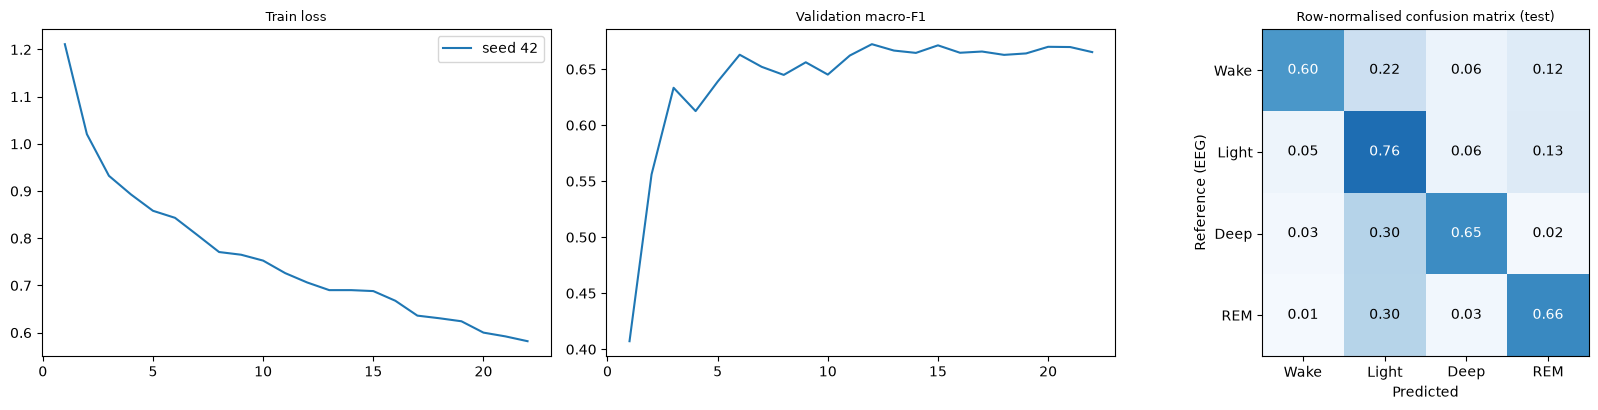

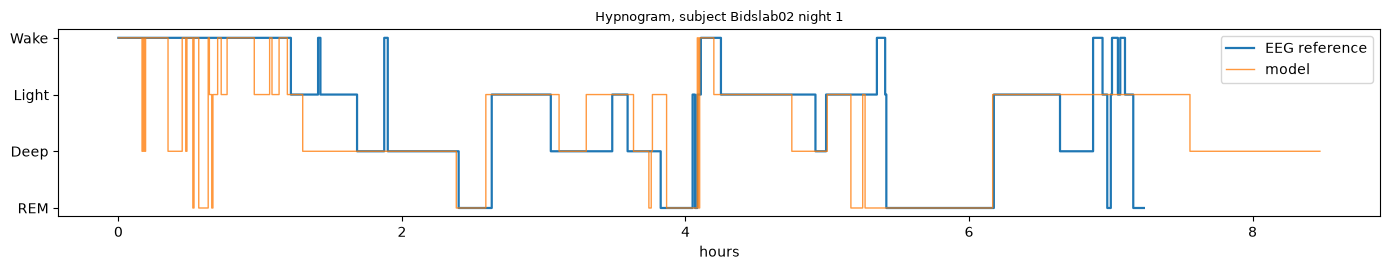

In [ ]:
names_ = task_info(cfg.task)[0]; WAKE = 0; REM_C = len(names_) - 1; DEEP_C = names_.index("Deep") if "Deep" in names_ else names_.index("N3")
def sleep_metrics(stage):
    valid = stage >= 0; sl = valid & (stage != WAKE); nv = int(valid.sum())
    run = np.convolve(sl.astype(int), np.ones(3, int), "valid") == 3
    return dict(TST_min=sl.sum() * cfg.epoch_sec / 60, SE_pct=100 * sl.sum() / max(nv, 1), SOL_min=(np.argmax(run) * cfg.epoch_sec / 60) if run.any() else np.nan,
                REM_pct=100 * ((stage == REM_C) & valid).sum() / max(sl.sum(), 1), DEEP_pct=100 * ((stage == DEEP_C) & valid).sum() / max(sl.sum(), 1), valid_frac=nv / len(stage))
rows = []
for r in per_night:
    ok = r["y"] >= 0
    if ok.sum() < 100: continue
    ref, est = sleep_metrics(r["y"]), sleep_metrics(np.where(ok, r["pred"], UNKNOWN))
    rows.append({**{f"ref_{k}": v for k, v in ref.items()}, **{f"est_{k}": v for k, v in est.items()}, "subject": r["subject"]})
sm = pd.DataFrame(rows); ba = []
for k in ["TST_min", "SE_pct", "SOL_min", "REM_pct", "DEEP_pct"]:
    d = (sm[f"est_{k}"] - sm[f"ref_{k}"]).dropna()
    if len(d): ba.append(dict(metric=k, bias=d.mean(), LoA_lo=d.mean() - 1.96 * d.std(), LoA_hi=d.mean() + 1.96 * d.std(), MAE=d.abs().mean(), n_nights=len(d)))
print(TITLE_TAG + "agreement with the EEG reference (est - ref), test nights, first seed:"); show(pd.DataFrame(ba).set_index("metric").round(2) if ba else pd.DataFrame())
if len(sm): print(f"mean valid fraction of epochs per night: {sm.ref_valid_frac.mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for res in RESULTS[MAIN]:
    h = pd.DataFrame(res["history"])
    if len(h): ax[0].plot(h.epoch, h.train_loss, label=f"seed {res['seed']}"); ax[1].plot(h.epoch, h.val_macro_f1, label=f"seed {res['seed']}")
ax[0].set_title(TITLE_TAG + "Train loss", fontsize=9); ax[1].set_title(TITLE_TAG + "Validation macro-F1", fontsize=9); ax[0].legend()
cmn = pooled_cm / pooled_cm.sum(1, keepdims=True).clip(1); ax[2].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax[2].set(xticks=range(K), yticks=range(K), xticklabels=names_, yticklabels=names_, xlabel="Predicted", ylabel="Reference (EEG)"); ax[2].set_title(TITLE_TAG + "Row-normalised confusion matrix (test)", fontsize=9)
for i in range(K):
    for j in range(K): ax[2].text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > .5 else "black")
plt.tight_layout(); plt.savefig(WORK / "fig_overview.png", dpi=150); plt.show()
r0 = per_night[0]; fig, ax = plt.subplots(figsize=(14, 2.8)); t_ = np.arange(len(r0["y"])) * cfg.epoch_sec / 3600
ax.step(t_, np.where(r0["y"] >= 0, r0["y"], np.nan), label="EEG reference", lw=1.6); ax.step(t_, r0["pred"], label="model", lw=1, alpha=.8)
ax.set(yticks=range(K), yticklabels=names_, xlabel="hours"); ax.set_title(f"{TITLE_TAG}Hypnogram, subject {r0['subject']} night {r0['night']}", fontsize=9); ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.savefig(WORK / "fig_hypnogram.png", dpi=150); plt.show()

## 17. Explainability: grouped permutation importance
Channels are redundant views of four signals, so **groups** (HR group, motion group, sampling density, and (in the interaction ablation) HR-motion features) are permuted jointly (one permutation of epochs applied to all channels in the group); single-channel rows are kept for reference. This is a descriptive reliance measure on the held-out test subjects of an already-selected model, not a model-selection step. Pooling-attention weights are shown only as a hint.

grouped permutation: 100%|██████████| 13/13 [03:12<00:00, 14.78s/it]

baseline test macro-F1 = 0.6851; drop when the group is permuted:
HR group              0.2086
single: hr_std        0.1802
Motion group          0.0933
single: hr            0.0266
single: hr_slope      0.0233
single: acc_mag       0.0090
single: acc_energy    0.0025
single: acc_jerk      0.0009
single: acc_y        -0.0001
HR density           -0.0009
single: hr_density   -0.0009
single: acc_z        -0.0014
single: acc_x        -0.0021


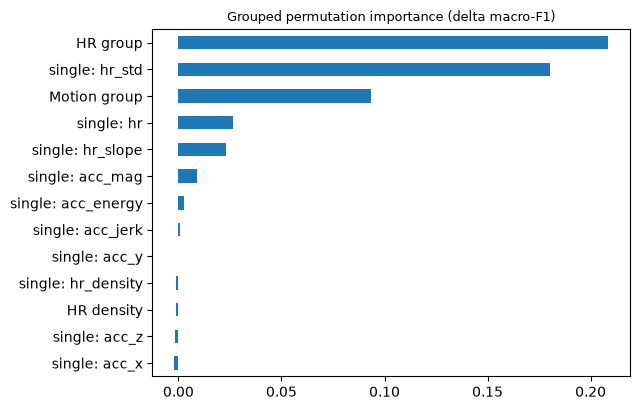


mean pooling-attention by reference stage (a hint, not an explanation):


,Wake,Light,Deep,REM
hr,0.153,0.143,0.169,0.138
hr_slope,0.225,0.289,0.284,0.290
hr_std,0.275,0.325,0.294,0.365
acc_x,0.013,0.015,0.017,0.012
acc_y,0.015,0.019,0.022,0.015
acc_z,0.013,0.016,0.017,0.012
acc_mag,0.118,0.056,0.054,0.048
acc_jerk,0.109,0.070,0.077,0.062
acc_energy,0.066,0.048,0.043,0.045
hr_density,0.013,0.017,0.022,0.013


In [ ]:
# TEST-SUBJECT ANALYSIS — exploratory (test looked at); opt-in only.
if cfg.run_permutation_importance:
    xc = replace(cfg, seed=SEEDS[0]); xres = RESULTS[MAIN][0]
    xmodel = build_model(xc, K).to(DEVICE); xmodel.load_state_dict(safe_load_checkpoint(BUNDLE.work / "runs" / run_tag(xc, BUNDLE) / "best.pt", run_identity(xc, BUNDLE), map_location=DEVICE)["model"]); xmodel.eval()
    xte = NightStore(BUNDLE.keys_of("test"), xc, BUNDLE, preload=False); xmode = xres["chosen_mode"]
    base_f1 = evaluate(xmodel, xte, xc, mode=xmode)["stats"]["macro_f1"]; nodes_ = list(xc.nodes); groups = {}
    for gname, gset in (("HR group", HR_G), ("Motion group", MO_G), ("HR density", {"hr_density"})):
        idx = [i for i, n in enumerate(nodes_) if n in gset]
        if idx: groups[gname] = idx
    for i, n in enumerate(nodes_): groups[f"single: {n}"] = [i]
    imp = {g: base_f1 - np.nanmean([evaluate(xmodel, xte, xc, mode=xmode, shuffle_idx=idx, seed=s)["stats"]["macro_f1"] for s in range(3)]) for g, idx in tqdm(groups.items(), desc="grouped permutation")}
    imp = pd.Series(imp).sort_values(ascending=False); print(f"{TITLE_TAG}baseline test macro-F1 = {base_f1:.4f}; drop when the group is permuted:\n{imp.round(4).to_string()}")
    imp.sort_values().plot.barh(figsize=(6.5, 4.2)); plt.title(TITLE_TAG + "Grouped permutation importance (delta macro-F1)", fontsize=9); plt.tight_layout(); plt.savefig(WORK / "fig_importance.png", dpi=150); plt.show()
    pr = evaluate(xmodel, xte, xc, mode="full", return_pool=True)["per_night"]
    if pr and pr[0]["pool"] is not None:
        att = pd.DataFrame({names_[k]: np.mean(np.concatenate([r["pool"][r["y"] == k] for r in pr if (r["y"] == k).any()]), 0) for k in range(K) if any((r["y"] == k).any() for r in pr)}, index=nodes_)
        print("\nmean pooling-attention by reference stage (a hint, not an explanation):"); show(att.round(3))

## 18. Reproducibility artifacts
Saved under the run's work directory: the split manifest (`split_manifest.json`, written when the data were prepared), dataset file manifest, label mapping, preprocessing and model configuration, seeds, per-run best checkpoint / history / metrics (inside each `runs/<tag>/`), personalization settings and results, model comparison, software versions and device. Every artifact carries the `data_source` label.

In [ ]:
import sklearn
assert cfg_hash(cfg) == CFG_HASH_AT_START, "the global configuration was modified after it was defined"
dm = [dict(subject=s, night=n, files={f: _stat(BUNDLE.night_dirs[(s, n)] / f)[1:] for f in ("hr.csv", "motion.csv", "labels.mat")}) for s, n in sorted(BUNDLE.night_dirs, key=lambda k: (num_key(k[0]), num_key(k[1])))]
(WORK / "dataset_manifest.json").write_text(json.dumps(dict(data_source=BUNDLE.data_source, root=str(BUNDLE.root), dataset_fp=BUNDLE.dataset_fp, files=dm), default=str))
(WORK / "label_mapping.json").write_text(json.dumps(dict(encoding=asdict(BUNDLE.enc), evidence=BUNDLE.enc.evidence, label_source=cfg.label_source, task=cfg.task, task_grouping=TASKS[cfg.task]["grouping"],
                                                          observed_raw_counts=BUNDLE.label_check["raw_counts"], label_check_warnings=BUNDLE.label_check["warnings"]), indent=1, default=str))
BUNDLE.qc.drop(columns=[c_ for c_ in ("label_report", "hr_file", "motion_file") if c_ in BUNDLE.qc]).to_csv(WORK / "qc_table.csv", index=False)
rep = dict(data_source=BUNDLE.data_source, run_label=RUN_LABEL, config=asdict(cfg), cfg_hash=CFG_HASH_AT_START, prep=prep_config(cfg), prep_version=PREP_VERSION, split_hash=BUNDLE.split_hash,
           dataset_fp=BUNDLE.dataset_fp, seeds=SEEDS, experiments=list(EXPERIMENTS), torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
           sklearn=sklearn.__version__, python=platform.python_version(), platform=platform.platform(), device=str(DEVICE),
           gpus=[torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())] if torch.cuda.is_available() else [],
           personalization=dict(ks=cfg.adapt_ks, epochs=cfg.adapt_epochs, lr=cfg.adapt_lr, windows=cfg.adapt_windows, scope=cfg.adapt_scope, control=cfg.adapt_control))
(WORK / "reproducibility.json").write_text(json.dumps(rep, indent=2, default=str)); print("saved artifacts to", WORK)

saved artifacts to /home/rj2826/ai-research/sleep/sleepchannelnet_v8_preprocessing_audit_work_REAL


## 19. Real-data integrity validation

These checks operate on the real dataset already loaded by `prepare_data`. They do not generate substitute data, create artificial recordings, or train on a synthetic dataset.

In [ ]:
# Real-data-only integrity checks. No synthetic dataset is generated.
REAL_DATA_CHECKS = []
def real_check(name, condition, detail=""):
    if not bool(condition):
        raise AssertionError(f"REAL-DATA CHECK FAILED: {name}. {detail}")
    REAL_DATA_CHECKS.append(name)
    print("PASS:", name)

real_check("bundle is explicitly marked REAL", BUNDLE.data_source == "REAL")
real_check("dataset root exists", BUNDLE.root.exists(), str(BUNDLE.root))
real_check("all discovered nights have expected source files",
           all(all((d / f).is_file() for f in ("hr.csv", "motion.csv", "labels.mat"))
               for d in BUNDLE.night_dirs.values()))
real_check("train/validation/test subject sets are disjoint",
           not (set(BUNDLE.split["train"]) & set(BUNDLE.split["val"]) or
                set(BUNDLE.split["train"]) & set(BUNDLE.split["test"]) or
                set(BUNDLE.split["val"]) & set(BUNDLE.split["test"])))
real_check("split covers all eligible subjects",
           set(BUNDLE.split["train"]) | set(BUNDLE.split["val"]) | set(BUNDLE.split["test"]) ==
           {s for s, _ in BUNDLE.eligible_keys})
real_check("eligible nights have cache files",
           len(BUNDLE.eligible_keys) > 0 and all((BUNDLE.cache / f"{s}__{n}.npz").is_file()
                                             for s, n in BUNDLE.eligible_keys))
real_check("train/validation/test each contain eligible nights",
           all(len(BUNDLE.keys_of(p)) > 0 for p in ("train", "val", "test")))
print(f"\\nREAL-DATA INTEGRITY CHECKS: {{len(REAL_DATA_CHECKS)}} passed. No synthetic data was generated.")


## 20. Final run summary

Healthy-population longitudinal monitoring only. Published SLAMSS-IFS reference: Accuracy 71.04%, Macro-F1 0.7079 (external paper values; this notebook does not claim reproduction). JEPA did not improve in the recorded run; see Section 13. No revised ablation has been executed unless a fresh output and experiment record is present.

In [ ]:
banner()
print(f"data source: {BUNDLE.data_source} | run label: {RUN_LABEL} | split {BUNDLE.split_hash} | train/val/test subjects: {len(BUNDLE.split['train'])}/{len(BUNDLE.split['val'])}/{len(BUNDLE.split['test'])}")
print("dataset root:", BUNDLE.root)
print("test subjects:", BUNDLE.split["test"])
print("models trained:", list(RESULTS), "| seeds:", SEEDS, "| personalization:", "ran" if PERS_ROWS is not None else "not run")
print("real-data integrity checks:", len(REAL_DATA_CHECKS), "passed")
assert BUNDLE.data_source == "REAL"
assert cfg.subject_limit is None, "Full-dataset mode requires subject_limit=None."
assert cfg_hash(cfg) == CFG_HASH_AT_START, "Configuration changed during execution."
if "JEPA_RESULT" in globals() and JEPA_RESULT is not None:
    print("SleepJEPA pretraining + fine-tuning:", "completed" if "stats" in JEPA_RESULT else "result unavailable")


## 21. Requested ablation suite (opt-in; validation selects, test reports once)

The original 10-feature model and `SleepChannelNet` remain available. The current identity-graph configuration is only a no-cross-channel-interaction proxy; exact SLAMSS-IFS reproduction (including its intra-epoch LSTM and preprocessing protocol) is not yet implemented or verified, so do not label it an exact reimplementation or interpret differences as gains over the paper. Toggle one experiment at a time in `ABLATION_TOGGLES`; the fixed subject-level split seed remains 0 and no test-set tuning is allowed. The default below is all off to prevent accidental expensive training. The SLAMSS-IFS published numbers are external reference values, not reproduced results. Exact baseline alignment requires checking preprocessing and label conventions before interpreting gains.

`SleepChannelNet_SE` substitutes shared per-channel CNN + SE channel recalibration for DenseGAT and retains attention pooling, bidirectional GRU, epoch skip connection, `hr_density`, frequency and time inputs. Its GRU hidden width is capped at 64 to meet the requested parameter budget; the runner checks the SE model against 80% of the existing model before training. The baseline defaults remain 10 input nodes; `all13` enables three derived interaction channels for the feature ablation. Their reactivity/coupling features use centered or forward windows and therefore model retrospective staging, not causal live inference.

Transition penalty and Viterbi decoding are independent toggles. Viterbi transitions use only training-subject empirical frequencies with Laplace smoothing. The transition penalty uses the requested fixed cost matrix and validation-only lambda selection.

The model currently uses GroupNorm throughout; it has no BatchNorm running statistics. The unsupervised adaptation therefore freezes the feature backbone and optionally entropy-minimizes only the classification head on unlabeled first-night windows. This is the implemented label-free alternative; it does not claim BN-stat adaptation. The supervised adaptation is retained under the explicit name `adapt_model_supervised_ceiling`.

Ablation outputs include classification summaries, per-class F1, subject-bootstrap confidence intervals, and model-wise clinical Bland-Altman bias/limits and subject-bootstrap 95% CIs. The interaction importance toggle reports a descriptive test-set permutation delta after model selection, not for tuning. Subject-level bootstrap intervals are required for every claim. No metrics are populated until the opt-in runs execute.


In [ ]:
# Opt-in runner and unsupervised adaptation helpers. No training runs by default.
ABLATION_TOGGLES = {"se_attention": False, "hr_motion_features": False, "transition_penalty": False, "viterbi": False, "unsupervised_personalization": False, "interaction_importance": False}
ABLATION_LAMBDAS = (0.05, 0.10, 0.20)  # candidates only; choose by validation macro-F1 before the single test report

def adapt_model_unsupervised(base, c, b, adapt_keys, seed, entropy=True):
    """Unlabeled test-time adaptation: freeze backbone; optional entropy-only head update. No EEG labels read."""
    model=copy.deepcopy(base).to(DEVICE); model.eval()
    for name,p in model.named_parameters(): p.requires_grad_(name.startswith("head."))
    store=NightStore(adapt_keys,c,b,preload=False); opt=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=1e-4)
    ds=TrainWindows(store,min(c.seq_len,min(store.n_epochs)),12,seed=seed)
    loader=DataLoader(ds,batch_size=min(8,len(ds)),shuffle=False,num_workers=0)
    if entropy:
        for _ in range(5):
            model.train()
            for X,meta,_ignored_y in loader:
                X,meta=X.to(DEVICE),meta.to(DEVICE); opt.zero_grad(set_to_none=True)
                p=torch.softmax(model(X,meta).float(),-1).clamp_min(1e-8); loss=-(p*p.log()).sum(-1).mean()
                loss.backward(); opt.step()
    return model.eval()

def select_transition_lambda_on_validation(c,b,lambdas=ABLATION_LAMBDAS):
    """Train candidates using TRAIN subjects; choose lambda by VALIDATION macro-F1 only; never evaluate test here.
    Results are cached per (config, dataset fingerprint) so restarts do not retrain."""
    cache_path = b.work / f"transition_lambda_sweep_{_h([cfg_hash(c), b.dataset_fp, list(lambdas)], 10)}.pkl"
    if cache_path.exists():
        cached = pickle.load(open(cache_path, "rb"))
        print(f"Reusing cached lambda sweep: {cached['scores']} -> {cached['best']}")
        return replace(c, transition_lambda=float(cached["best"]))
    tr=NightStore(b.keys_of("train"),c, b, preload=True); va=NightStore(b.keys_of("val"),c,b,preload=False)
    scores=[]
    for lam in lambdas:
        cc=replace(c,transition_lambda=float(lam),resume=True)
        ident=run_identity(cc,b,extra={"validation_lambda_sweep":True})
        out=b.work/"runs"/(run_tag(cc,b)+"_validation_lambda_sweep")
        _model,_hist,_mode,_val=fit(cc,b,tr,va,out,ident)
        score=float(_val.get(_mode,float("nan"))); scores.append((score,float(lam)))
    best=max(scores,key=lambda x:x[0]); print("validation-only transition lambda scores (macro-F1, lambda):",scores,"selected",best[1])
    pickle.dump({"scores":scores,"best":best[1]}, open(cache_path,"wb"))
    return replace(c,transition_lambda=best[1])

def requested_ablation_configs(c):
    """Return cumulative rows through the deepest enabled ablation, preserving ablation order."""
    deep = any(ABLATION_TOGGLES[k] for k in ("hr_motion_features","transition_penalty","viterbi","unsupervised_personalization","interaction_importance"))
    use_se = ABLATION_TOGGLES["se_attention"] or deep
    use_features = ABLATION_TOGGLES["hr_motion_features"] or any(ABLATION_TOGGLES[k] for k in ("transition_penalty","viterbi","unsupervised_personalization","interaction_importance"))
    use_transition = ABLATION_TOGGLES["transition_penalty"] or any(ABLATION_TOGGLES[k] for k in ("viterbi","unsupervised_personalization"))
    use_viterbi = ABLATION_TOGGLES["viterbi"] or ABLATION_TOGGLES["unsupervised_personalization"]
    rows=[("SLAMSS-IFS architecture proxy (not exact reproduction)",dict(model_type="slamss_proxy",graph_mode="identity",nodes=tuple(BASE_NODES),transition_lambda=0.,use_viterbi_decoding=False))]
    if use_se: rows.append(("+ SE-Net channel attention",dict(model_type="channel_se",nodes=tuple(BASE_NODES))))
    if use_features: rows.append(("+ HR-Motion interaction features",dict(model_type="channel_se",nodes=tuple(NODES_ALL),use_hr_motion_features=True)))
    if use_transition: rows.append(("+ Transition-penalty loss",dict(model_type="channel_se",nodes=tuple(NODES_ALL),use_hr_motion_features=True,transition_lambda=0.10)))
    if use_viterbi: rows.append(("+ Viterbi decoding",dict(model_type="channel_se",nodes=tuple(NODES_ALL),use_hr_motion_features=True,transition_lambda=0.10,use_viterbi_decoding=True)))
    if ABLATION_TOGGLES["unsupervised_personalization"]: rows.append(("+ Unsupervised personalization",dict(model_type="channel_se",nodes=tuple(NODES_ALL),use_hr_motion_features=True,transition_lambda=0.10,use_viterbi_decoding=True)))
    return rows

if any(ABLATION_TOGGLES.values()):
    if "BUNDLE" not in globals(): raise RuntimeError("Run data preparation before requested ablations.")
    ABLATION_RESULTS={}; ABLATION_CONFIGS={}; ABLATION_SUMMARY=[]; INTERACTION_IMPORTANCE=[]
    _base_c=replace(cfg,model_type="channel_attn",graph_mode="complete",nodes=tuple(BASE_NODES))
    _se_c=replace(cfg,model_type="channel_se",nodes=tuple(BASE_NODES))
    _n_base=sum(p.numel() for p in build_model(_base_c,K).parameters()); _n_se=sum(p.numel() for p in build_model(_se_c,K).parameters())
    print(f"parameter audit: existing complete-graph model={_n_base:,}; SE model={_n_se:,}; ratio={_n_se/_n_base:.3f}")
    if _n_se > 0.80*_n_base: raise RuntimeError("SE model exceeds the requested 80% parameter target; adjust the SE model before training.")
    for _name,_overrides in requested_ablation_configs(cfg):
        _c=replace(cfg,**_overrides)
        if _c.transition_lambda>0: _c=select_transition_lambda_on_validation(_c,BUNDLE)
        ABLATION_CONFIGS[_name]=_c
        # The existing run_experiment uses validation for checkpoint/mode selection and test once for reporting.
        ABLATION_RESULTS[_name]=[run_experiment(replace(_c,seed=_seed),BUNDLE) for _seed in SEEDS]
        if ABLATION_TOGGLES["interaction_importance"] and "hr_motion_coupling" in _c.nodes:
            _xc=replace(_c,seed=SEEDS[0]); _identity=run_identity(_xc,BUNDLE)
            _xm=build_model(_xc,K).to(DEVICE); _rd=BUNDLE.work/"runs"/run_tag(_xc,BUNDLE)
            _xm.load_state_dict(safe_load_checkpoint(_rd/"best.pt",_identity,map_location=DEVICE)["model"]); _xm.eval()
            _xt=NightStore(BUNDLE.keys_of("test"),_xc,BUNDLE,preload=False); _base=evaluate(_xm,_xt,_xc,mode=ABLATION_RESULTS[_name][0]["chosen_mode"])["stats"]["macro_f1"]
            _idx=[_xc.nodes.index(_n) for _n in INTERACTION_NODES]; _drops=[]
            for _permseed in range(3): _drops.append(_base-evaluate(_xm,_xt,_xc,mode=ABLATION_RESULTS[_name][0]["chosen_mode"],shuffle_idx=_idx,seed=_permseed)["stats"]["macro_f1"])
            INTERACTION_IMPORTANCE.append(dict(model=_name,feature_group="HR-motion interaction channels",baseline_macro_f1=_base,permutation_delta_macro_f1=float(np.mean(_drops))))
        _cm,_pooled,_subjects,_ci,_nights,_night_table=full_report(ABLATION_RESULTS[_name],BUNDLE,_c,_name)
        ABLATION_SUMMARY.append(dict(model=_name,accuracy=_pooled["accuracy"],macro_f1=_pooled["macro_f1"],kappa=_pooled["kappa"],
            subject_mean_accuracy=float(_subjects.accuracy.mean()),subject_mean_macro_f1=float(_subjects.macro_f1.mean()),subject_mean_kappa=float(_subjects.kappa.mean())))
    if ABLATION_TOGGLES["unsupervised_personalization"]:
        _final_name=next(reversed(ABLATION_CONFIGS))
        PERS_ROWS, _pers_plan=run_personalization(replace(ABLATION_CONFIGS[_final_name],run_personalization=False),BUNDLE,ABLATION_RESULTS[_final_name][0])
        PERS_ROWS.to_csv(BUNDLE.work/"unsupervised_personalization_and_supervised_ceiling.csv",index=False)
        PERS_SUMMARY=analyse_personalization(PERS_ROWS,cfg.n_boot,seed=cfg.seed)
        display(PERS_SUMMARY.round(4)); PERS_SUMMARY.to_csv(BUNDLE.work/"personalization_subject_bootstrap_summary.csv",index=False)
    ABLATION_TABLE=pd.DataFrame(ABLATION_SUMMARY)
    display(ABLATION_TABLE.round(4)); ABLATION_TABLE.to_csv(BUNDLE.work/"requested_ablation_summary.csv",index=False)
    clinical_rows=[]
    for _name,_runs in ABLATION_RESULTS.items():
        for _res in _runs:
            for _r in _res["per_night"]:
                _ok=_r["y"]>=0
                if _ok.sum()<100: continue
                _ref=sleep_metrics(_r["y"]); _est=sleep_metrics(np.where(_ok,_r["pred"],UNKNOWN))
                clinical_rows.append(dict(model=_name,seed=_res["seed"],subject=_r["subject"],night=_r["night"],
                    **{f"ref_{k}":v for k,v in _ref.items()},**{f"est_{k}":v for k,v in _est.items()}))
    _clinical=pd.DataFrame(clinical_rows); _ba_rows=[]
    for _name,_mg in _clinical.groupby("model"):
        for _key in ("TST_min","SE_pct","SOL_min","REM_pct","DEEP_pct"):
            _dset=_mg[["subject",f"ref_{_key}",f"est_{_key}"]].dropna()
            if _dset.empty: continue
            _subs=_dset.subject.unique(); _diff=_dset[f"est_{_key}"].to_numpy()-_dset[f"ref_{_key}"].to_numpy()
            _bias=float(_diff.mean()); _lo=float(_bias-1.96*_diff.std()); _hi=float(_bias+1.96*_diff.std()); _rng=np.random.default_rng(cfg.seed)
            _boot=np.empty((cfg.n_boot,3),float)
            for _bi in range(cfg.n_boot):
                _draw=_rng.choice(_subs,len(_subs),replace=True); _parts=[_dset[_dset.subject==_ss] for _ss in _draw]
                _bd=np.concatenate([(z[f"est_{_key}"].to_numpy()-z[f"ref_{_key}"].to_numpy()) for z in _parts]); _bb=float(_bd.mean())
                _boot[_bi]=(_bb,_bb-1.96*_bd.std(),_bb+1.96*_bd.std())
            _ci=np.percentile(_boot,[2.5,97.5],axis=0)
            _ba_rows.append(dict(model=_name,metric=_key,bias=_bias,LoA_lo=_lo,LoA_hi=_hi,n_subjects=len(_subs),n_nights=len(_dset),
                bias_ci_lo=_ci[0,0],bias_ci_hi=_ci[1,0],LoA_lo_ci_lo=_ci[0,1],LoA_lo_ci_hi=_ci[1,1],LoA_hi_ci_lo=_ci[0,2],LoA_hi_ci_hi=_ci[1,2]))
    ABLATION_BA=pd.DataFrame(_ba_rows); display(ABLATION_BA.round(3)); ABLATION_BA.to_csv(BUNDLE.work/"requested_ablation_clinical_bland_altman.csv",index=False)
    if INTERACTION_IMPORTANCE:
        INTERACTION_IMPORTANCE=pd.DataFrame(INTERACTION_IMPORTANCE); display(INTERACTION_IMPORTANCE); INTERACTION_IMPORTANCE.to_csv(BUNDLE.work/"interaction_permutation_importance.csv",index=False)
    print("Each full_report above includes pooled, per-subject and per-night metrics, per-class F1, and subject-bootstrap CIs. Clinical Bland-Altman point estimates are saved by model; no revised experiment has been executed until these opt-in cells are run.")
else:
    print("Requested ablation suite is defined; all toggles are off. No additional training was run.")
